# Laboratorio 3 - La tarea de clasificación

*Presentado por:*
- Shaiel Jiménez - 202323846
- Juan Esteban Triviño - 202315338

*ISIS2611 - Aprendizaje de Máquina / Sección 5*

*Profesor: Rubén Manrique*

**Contenido**

- [Introducción](#introduccion)
- [Configuración del entorno](#entorno)
- [Actividad 1 - Exploración de los datos](#actividad1)
- [Actividad 2 - Limpieza y preparación](#actividad2)
- [Actividad 3 - Regresión logística](#actividad3)
- [Actividad 4 - Árboles de decisión](#actividad4)
- [Actividad 5 - Random Forest](#actividad5)
- [Actividad 6 - Balanceo de clases en Restaurante(<20)](#actividad6)
- [Actividad 7 - Tabla comparativa](#actividad7)
- [Actividad 8 - Variables más relevantes](#actividad8)
- [Actividad 10 - Predicciones sobre los datos de prueba](#actividad10)
- [Análisis de resultados](#analisis)

## <a id="introduccion"></a> Introducción

Ruta Alpes es una aplicación de conducción que recomienda cupones, como descuentos en cafeterías y restaurantes cercanos a la ruta, y quiere saber cuándo un conductor tiene más probabilidad de aceptarlos para no enviar ofertas irrelevantes. Este laboratorio construye, para los cupones de Cafetería y Restaurante(<20), modelos que predicen si el conductor acepta (*acepta_cupon*). Compara regresión logística, árbol de decisión y Random Forest, evalúa si balancear las clases ayuda en Restaurante, identifica las variables más relevantes y analiza los riesgos de sesgo de personalizar con datos demográficos.

**Resumen de decisiones.** Cada cupón se modela por separado, con un pipeline que imputa y codifica solo con el entrenamiento de cada fold. La partición es 75/25 estratificada y los hiperparámetros se eligen con validación cruzada y F1 macro. Como los conductores se repiten entre escenarios, esa validación separa a los conductores, para no premiar a los modelos que los memorizan. El modelo final se elige con esa misma validación: Random Forest en Cafetería (F1 macro de 0.711 en prueba) y Random Forest con SMOTE en Restaurante (0.687), con diferencias pequeñas frente a los otros algoritmos.

## <a id="entorno"></a> Configuración del entorno

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold, StratifiedGroupKFold,
                                     cross_val_score, cross_validate)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, make_scorer

# SMOTE y Pipeline de imblearn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
DATA_DIR = Path("data/raw")
RUTA_DATOS = DATA_DIR / "Lab3_Datos.xlsx"
RUTA_PRUEBA = DATA_DIR / "Lab3_datos_Prueba.xlsx"
RUTA_DICCIONARIO = DATA_DIR / "Lab3_diccionario_Datos.xlsx"

# Validación cruzada por conductor (un mismo conductor no queda a la vez en entrenamiento y validación),
# con los mismos folds para todos los modelos
cv_conductor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Folds aleatorios, solo para contrastarlos con los de conductor (Actividad 5)
cv_aleatorio = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Archivos de datos:", [p.name for p in DATA_DIR.glob("*.xlsx")])

Archivos de datos: ['Lab3_Datos.xlsx', 'Lab3_diccionario_Datos.xlsx', 'Lab3_datos_Prueba.xlsx']


## <a id="actividad1"></a> Actividad 1 - Exploración de los datos

### 1.1 Carga y estructura

Se cargan los datos de entrenamiento, los de prueba y el diccionario. Lo que se lee se guarda en *datos_originales* y *prueba_original*, y se trabaja siempre sobre las copias *df* y *prueba*, para no alterar los originales.

In [3]:
datos_originales = pd.read_excel(RUTA_DATOS)
prueba_original = pd.read_excel(RUTA_PRUEBA)
diccionario = pd.read_excel(RUTA_DICCIONARIO)

# Copias de trabajo: los originales no se modifican
df = datos_originales.copy()
prueba = prueba_original.copy()

print(f"Entrenamiento: {df.shape} | Prueba: {prueba.shape} | Diccionario: {diccionario.shape}")
pd.DataFrame({"tipo": df.dtypes, "valores_unicos": df.nunique()})

Entrenamiento: (12664, 26) | Prueba: (20, 25) | Diccionario: (26, 3)


,tipo,valores_unicos
destino,str,3
acompanante,str,4
clima,str,3
temperatura,int64,3
hora,str,5
cupon,str,5
vigencia_cupon,str,2
genero,str,2
edad,str,8
estado_civil,str,5


In [4]:
cols_dic = set(diccionario["Variable"])
print("Columnas del diccionario que faltan en los datos:", cols_dic - set(df.columns))
print("Columnas de los datos que no están en el diccionario:", set(df.columns) - cols_dic)
print("Diferencia entre entrenamiento y prueba:", set(df.columns) ^ set(prueba.columns))

Columnas del diccionario que faltan en los datos: set()
Columnas de los datos que no están en el diccionario: set()
Diferencia entre entrenamiento y prueba: {'acepta_cupon'}


**Hallazgos.** Los datos coinciden con el diccionario y el archivo de prueba solo se diferencia en *acepta_cupon*, que es lo que se quiere predecir. Solo *temperatura* es numérica; el resto son categóricas, y *edad* mezcla números con textos como "menor de 21" y "50 o más". *tiempo_cupon_mayor_5min* tiene un único valor.

### 1.2 Valores nulos

Se revisa cuántos faltantes hay, en qué columnas y si siguen algún patrón.

In [5]:
nulos = df.isna().sum()
tabla_nulos = pd.DataFrame({"nulos": nulos, "%": (nulos / len(df) * 100).round(2)})
tabla_nulos[tabla_nulos["nulos"] > 0]

,nulos,%
vehiculo,12556,99.15
frecuencia_bar,107,0.84
frecuencia_cafeteria,217,1.71
frecuencia_comida_para_llevar,151,1.19
frecuencia_restaurante_menos_20,130,1.03
frecuencia_restaurante_20_a_50,189,1.49


In [6]:
print("Nulos en el archivo de prueba:", prueba.isna().sum()[lambda s: s > 0].to_dict())

# Los nulos de frecuencia_* ¿son del conductor o del escenario?
perfil = ["genero", "edad", "estado_civil", "tiene_hijos", "educacion", "ocupacion", "ingreso"]
frec = [c for c in df.columns if c.startswith("frecuencia_")]
print(f"Perfiles distintos de conductor: {df[perfil].drop_duplicates().shape[0]} en {len(df)} filas")

por_perfil = df.assign(nulo=df[frec].isna().any(axis=1)).groupby(perfil)["nulo"].mean()
print(f"Perfiles con nulos en frecuencia_*: {(por_perfil > 0).sum()} | con nulos en todas sus filas: {(por_perfil == 1).sum()}")

Nulos en el archivo de prueba: {'vehiculo': 20}
Perfiles distintos de conductor: 519 en 12664 filas
Perfiles con nulos en frecuencia_*: 33 | con nulos en todas sus filas: 29


**Hallazgos y decisiones.** *vehiculo* está vacía en el 99% de las filas y siempre en la prueba, así que se elimina. Las *frecuencia_\** tienen entre 0.8% y 1.7% de nulos y casi siempre faltan en todas las filas de un mismo conductor, es decir, son preguntas que esa persona no contestó. Como son pocos, se imputan con la moda dentro del pipeline, para que se calcule solo con el entrenamiento y no haya fuga de datos; eliminar filas quitaría conductores completos.

Además, hay solo 519 perfiles demográficos distintos en más de 12 mil filas, lo que significa que cada persona aparece en varios escenarios. Esto se afina en 1.5, con los hábitos de consumo.

### 1.3 Subconjuntos por tipo de cupón

El enunciado pide un modelo para Cafetería y otro para Restaurante(<20). Se modelan por separado porque lo que lleva a aceptar uno no tiene por qué llevar a aceptar el otro, y así se pueden comparar.

In [7]:
df["cupon"].value_counts().to_frame("filas")

,filas
cupon,
Cafetería,3986
Restaurante(<20),2776
Comida para llevar,2393
Bar,2017
Restaurante(20-50),1492


In [8]:
cafe = df[df["cupon"] == "Cafetería"].copy()
rest = df[df["cupon"] == "Restaurante(<20)"].copy()

print(f"Cafetería: {len(cafe)} | Restaurante(<20): {len(rest)} | Total: {len(cafe) + len(rest)} ({(len(cafe) + len(rest)) / len(df):.1%} del archivo)")
print("Cupones en la prueba:", prueba["cupon"].value_counts().to_dict())

Cafetería: 3986 | Restaurante(<20): 2776 | Total: 6762 (53.4% del archivo)
Cupones en la prueba: {'Cafetería': 10, 'Restaurante(<20)': 10}


**Hallazgos.** Los dos subconjuntos suman 6762 filas (53.4% del archivo); los demás cupones no se usan. En el archivo de prueba hay solo 10 filas de cada cupón, así que sirve para las predicciones finales pero no para elegir modelos. *cupon* es constante dentro de cada subconjunto y se elimina en la limpieza.

### 1.4 Distribución de la variable objetivo

Se mira cuántos aceptan y cuántos rechazan en cada cupón, porque de eso depende qué métricas usar.

In [9]:
dist = pd.concat({"Cafetería": cafe["acepta_cupon"], "Restaurante(<20)": rest["acepta_cupon"]}, names=["cupon"])
dist = dist.groupby("cupon").value_counts().to_frame("filas")
dist["%"] = (dist["filas"] / dist.groupby("cupon")["filas"].transform("sum") * 100).round(1)
dist

filas     %
cupon            acepta_cupon             
Cafetería        No             1997  50.1
                 Sí             1989  49.9
Restaurante(<20) Sí             1962  70.7
                 No              814  29.3

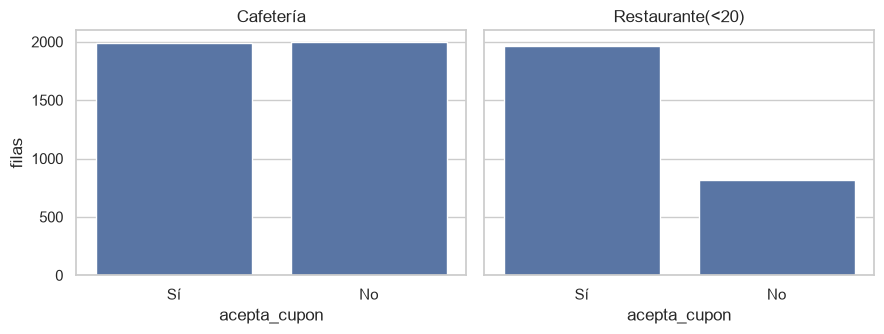

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, (nombre, datos) in zip(axes, [("Cafetería", cafe), ("Restaurante(<20)", rest)]):
    sns.countplot(data=datos, x="acepta_cupon", order=["Sí", "No"], ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("acepta_cupon")
axes[0].set_ylabel("filas")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Hallazgos.** En **Cafetería** las clases están parejas (49.9% acepta), mientras que en **Restaurante(<20)** acepta el 70.7% y rechaza el 29.3%, de modo que la clase minoritaria es el rechazo.

Con ese desbalance la exactitud engaña, ya que responder siempre "Sí" acertaría el 70.7% sin detectar ningún rechazo. Por eso se reportan precisión, recall y F1 por clase, y se usa el **F1 macro** (promedio del F1 de las dos clases) para elegir hiperparámetros. De aquí en adelante, F1 sin más significa F1 macro. La partición y los folds son estratificados para conservar la proporción de clases.

### 1.5 Duplicados y conductores repetidos

Se revisan las filas repetidas y si un mismo conductor aparece en varios escenarios.

In [11]:
features = [c for c in df.columns if c != "acepta_cupon"]

resumen = {}
for nombre, datos in [("Cafetería", cafe), ("Restaurante(<20)", rest)]:
    grupos = datos.groupby(features, dropna=False)["acepta_cupon"].agg(["nunique", "size"])
    resumen[nombre] = {
        "filas": len(datos),
        "duplicadas exactas": datos.duplicated().sum(),
        "grupos con mismas características y etiquetas distintas": (grupos["nunique"] > 1).sum(),
    }
pd.DataFrame(resumen)

,Cafetería,Restaurante(<20)
filas,3986,2776
duplicadas exactas,7,7
grupos con mismas características y etiquetas distintas,4,3


In [12]:
# El archivo no trae identificador de conductor: se aproxima con las variables que describen
# a la persona (perfil demográfico y hábitos de consumo), que no cambian entre escenarios.
def clave_conductor(d):
    return d[perfil + frec].fillna("NA").astype(str).agg("|".join, axis=1)

for d in (cafe, rest, prueba):
    d["conductor"] = clave_conductor(d)

for nombre, datos in [("Cafetería", cafe), ("Restaurante(<20)", rest)]:
    escenarios = datos["conductor"].value_counts()
    tr, te = train_test_split(datos, test_size=0.25, stratify=datos["acepta_cupon"], random_state=RANDOM_STATE)
    print(f"{nombre}: {len(escenarios)} conductores, {escenarios.median():.0f} escenarios por conductor (mediana), máximo {escenarios.max()}")
    print(f"   filas de test cuyo conductor aparece en train: {te['conductor'].isin(tr['conductor']).mean():.1%}")

conocidos = prueba["conductor"].isin(pd.concat([cafe["conductor"], rest["conductor"]]))
print(f"Archivo de prueba: {conocidos.sum()} de {len(prueba)} filas son de conductores presentes en el entrenamiento")

Cafetería: 565 conductores, 7 escenarios por conductor (mediana), máximo 28
   filas de test cuyo conductor aparece en train: 99.7%
Restaurante(<20): 567 conductores, 5 escenarios por conductor (mediana), máximo 26
   filas de test cuyo conductor aparece en train: 98.0%
Archivo de prueba: 20 de 20 filas son de conductores presentes en el entrenamiento


**Hallazgos.** Hay 7 filas duplicadas exactas por subconjunto, que se eliminan antes de partir para que una fila no quede en el entrenamiento y su copia en la prueba. También hay grupos de escenarios idénticos con respuestas distintas (4 en Cafetería y 3 en Restaurante), que no se tocan porque son ruido real del problema.

La encuesta original tiene varios escenarios por persona, pero no un identificador, así que como aproximación se agrupan las filas que comparten las doce variables de la persona. Salen unos 565 conductores, con una mediana de 5 a 7 escenarios cada uno; es un supuesto, no un dato.

Con una partición aleatoria, entre el 98% y el 99.7% de las filas de prueba son de conductores que ya estaban en el entrenamiento, igual que las 20 filas del archivo de prueba. Es un riesgo de **fuga por grupos**, porque un modelo flexible podría reconocer a la persona en lugar de aprender un patrón general. Por eso la validación cruzada de todas las búsquedas separa a los conductores (*StratifiedGroupKFold*), y de aquí en adelante se llama validación por conductor. La partición en entrenamiento y prueba se deja aleatoria y estratificada, porque coincide con el archivo de prueba.

### 1.6 Consistencia y validez de las categorías

Se revisa que los valores estén bien escritos, coincidan con el diccionario y no se contradigan entre columnas.

In [13]:
categoricas = [c for c in df.columns if c != "temperatura"]
tabla_valores = pd.DataFrame({
    "n_valores": [df[c].nunique() for c in categoricas],
    "valores": [
        "25 categorías (coinciden con el diccionario)" if c == "ocupacion"
        else ", ".join(df[c].dropna().unique())
        for c in categoricas
    ],
}, index=categoricas)

espacios = sum((df[c].dropna() != df[c].dropna().str.strip()).sum() for c in categoricas)
print("Valores con espacios sobrantes:", espacios)
tabla_valores

Valores con espacios sobrantes: 0


,n_valores,valores
destino,3,"Sin lugar urgente, Casa, Trabajo"
acompanante,4,"Solo, Amigo(s), Hijo(s), Pareja"
clima,3,"Soleado, Lluvioso, Nevado"
hora,5,"2:00 p.m., 10:00 a.m., 6:00 p.m., 7:00 a.m., 1..."
cupon,5,"Restaurante(<20), Cafetería, Comida para lleva..."
vigencia_cupon,2,"1 día, 2 horas"
genero,2,"Femenino, Masculino"
edad,8,"21, 46, 26, 31, 41, 50 o más, 36, menor de 21"
estado_civil,5,"Unión libre, Soltero(a), Casado(a), Divorciado..."
tiene_hijos,2,"Sí, No"


In [14]:
print("clima vs temperatura:")
print(pd.crosstab(df["clima"], df["temperatura"]), "\n")

complementarias = (df["misma_direccion"] != df["direccion_opuesta"]).all()
print("misma_direccion y direccion_opuesta siempre son opuestas:", complementarias)

anidadas = ((df["tiempo_cupon_mayor_25min"] == "Sí") <= (df["tiempo_cupon_mayor_15min"] == "Sí")).all()
print("Mayor de 25 min implica mayor de 15 min:", anidadas, "\n")

print("destino vs hora:")
print(pd.crosstab(df["destino"], df["hora"]), "\n")

print("Acompañante 'Hijo(s)' sin tener hijos:", ((df["acompanante"] == "Hijo(s)") & (df["tiene_hijos"] == "No")).sum())
print("Jubilados de 26 años:", ((df["ocupacion"] == "Jubilado(a)") & (df["edad"] == "26")).sum(), "| de 36 años:", ((df["ocupacion"] == "Jubilado(a)") & (df["edad"] == "36")).sum(),
      "| menores de 21 con pregrado:", ((df["edad"] == "menor de 21") & (df["educacion"] == "Pregrado")).sum())

clima vs temperatura:
temperatura    30    55    80
clima                        
Lluvioso        0  1208     0
Nevado       1404     0     0
Soleado       911  2628  6513 

misma_direccion y direccion_opuesta siempre son opuestas: True
Mayor de 25 min implica mayor de 15 min: True 

destino vs hora:
hora               10:00 a.m.  10:00 p.m.  2:00 p.m.  6:00 p.m.  7:00 a.m.
destino                                                                   
Casa                        0        1113          0       2120          0
Sin lugar urgente        2271         890       2005       1104          0
Trabajo                     0           0          0          0       3161 

Acompañante 'Hijo(s)' sin tener hijos: 17
Jubilados de 26 años: 22 | de 36 años: 22 | menores de 21 con pregrado: 22


**Hallazgos.** Los valores coinciden con el diccionario, sin variantes ni espacios sobrantes. La única diferencia de formato está en *ingreso*, pues el diccionario escribe los rangos sin espacios y los datos con espacios, así que el orden se define con el texto de los datos. *edad* mezcla números con "menor de 21" y "50 o más", por lo que se trata como ordinal y no como numérica.

Las relaciones entre columnas son coherentes. La nieve solo aparece a 30 °F y la lluvia a 55 °F, el trabajo siempre es a las 7:00 a.m. y quien está a más de 25 minutos también está a más de 15. Dos cosas llaman la atención. Por un lado, *misma_direccion* y *direccion_opuesta* son opuestas en todas las filas, así que se deja solo *misma_direccion*, porque dos columnas así causan multicolinealidad perfecta en la regresión logística. Por otro, hay 17 filas con acompañante "Hijo(s)" y *tiene_hijos* en "No", que se conservan porque pueden ser niños que viajan con el conductor sin ser sus hijos.

También hay combinaciones poco comunes, como jubilados de 26 o 36 años o menores de 21 con pregrado, en 22 filas cada una que parecen ser un solo encuestado (los conteos se muestran arriba). No son imposibles, así que se conservan.

Para los pipelines, las variables se codifican según su tipo. Son ordinales, con orden explícito, *hora*, *edad*, *educacion*, *ingreso* y las cinco *frecuencia_\**; binarias, *genero*, *tiene_hijos*, *vigencia_cupon*, *tiempo_cupon_mayor_15min*, *tiempo_cupon_mayor_25min* y *misma_direccion*; nominales, con one-hot, *destino*, *acompanante*, *clima*, *estado_civil* y *ocupacion*; y numérica solo *temperatura*.

### 1.7 Variables constantes o casi constantes

Una variable que casi no cambia no ayuda a separar a quienes aceptan de quienes rechazan. Se mide qué porcentaje de las filas tiene el valor más frecuente de cada una.

In [15]:
descartadas = ["vehiculo", "cupon", "direccion_opuesta"]
predictoras = [c for c in df.columns if c not in descartadas + ["acepta_cupon"]]

def dominancia(d):
    return d[predictoras].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)

tabla_dominancia = pd.DataFrame({"Cafetería (%)": dominancia(cafe), "Restaurante(<20) (%)": dominancia(rest)})
tabla_dominancia.sort_values("Cafetería (%)", ascending=False).round(1).head(6)

,Cafetería (%),Restaurante(<20) (%)
tiempo_cupon_mayor_5min,100.0,100.0
tiempo_cupon_mayor_25min,92.2,88.8
clima,86.8,80.4
misma_direccion,81.3,82.0
tiene_hijos,61.2,58.8
temperatura,60.1,56.4


In [16]:
for nombre, datos in [("Cafetería", cafe), ("Restaurante(<20)", rest)]:
    conteos = pd.concat([datos[c].value_counts() for c in predictoras if c != "temperatura"])
    raras = conteos[conteos < 30]
    print(f"{nombre}: {len(raras)} categorías con menos de 30 filas ->", raras.to_dict())

Cafetería: 4 categorías con menos de 30 filas -> {'Bachillerato incompleto': 28, 'Producción': 28, 'Limpieza y Mantenimiento de Edificios': 11, 'Agricultura, Pesca y Silvicultura': 11}
Restaurante(<20): 6 categorías con menos de 30 filas -> {'Viudo(a)': 29, 'Bachillerato incompleto': 18, 'Instalación, Mantenimiento y Reparación': 27, 'Producción': 25, 'Limpieza y Mantenimiento de Edificios': 10, 'Agricultura, Pesca y Silvicultura': 7}


**Hallazgos.** *tiempo_cupon_mayor_5min* vale "Sí" en el 100% de las filas y se elimina. Le siguen *tiempo_cupon_mayor_25min* (89% a 92% en "No"), *clima* (80% a 87% soleado) y *misma_direccion* (unas 8 de cada 10 en "No"), que se conservan porque variar poco no significa informar poco, y su efecto se mira en 1.8.

También hay categorías con muy pocas filas, sobre todo ocupaciones poco comunes y "Bachillerato incompleto", casi siempre de una sola persona. No se agrupan por ahora y, si aparece inestabilidad al modelar, se controla con la regularización o con *min_samples_leaf* en los árboles.

### 1.8 Relación de cada variable con la aceptación

Como casi todas las variables son categóricas, se compara el porcentaje que acepta en cada categoría. Para ordenar las variables se usa la **brecha de aceptación**, que es la diferencia en puntos porcentuales entre la categoría que más acepta y la que menos, tomando solo categorías de al menos 100 filas para que pocas personas no distorsionen el resultado. Es una mirada descriptiva que no implica causalidad, y las variables con muchas categorías tienden a tener brechas mayores.

In [17]:
variables = [c for c in predictoras if c != "tiempo_cupon_mayor_5min"]  # esta es constante

def brecha_aceptacion(datos, minimo=100):
    brechas = {}
    for c in variables:
        t = (datos["acepta_cupon"] == "Sí").groupby(datos[c]).agg(["mean", "size"])
        t = t[t["size"] >= minimo]
        brechas[c] = (t["mean"].max() - t["mean"].min()) * 100
    return pd.Series(brechas)

tabla_brecha = pd.DataFrame({
    "Cafetería": brecha_aceptacion(cafe),
    "Restaurante(<20)": brecha_aceptacion(rest),
})
tabla_brecha.sort_values("Cafetería", ascending=False).round(1)

,Cafetería,Restaurante(<20)
frecuencia_cafeteria,49.9,13.9
edad,27.6,11.7
ingreso,26.5,20.1
ocupacion,23.3,21.2
hora,22.7,32.1
destino,21.9,23.6
tiempo_cupon_mayor_25min,16.7,42.9
acompanante,15.7,16.2
vigencia_cupon,15.2,24.3
frecuencia_restaurante_20_a_50,14.0,6.5


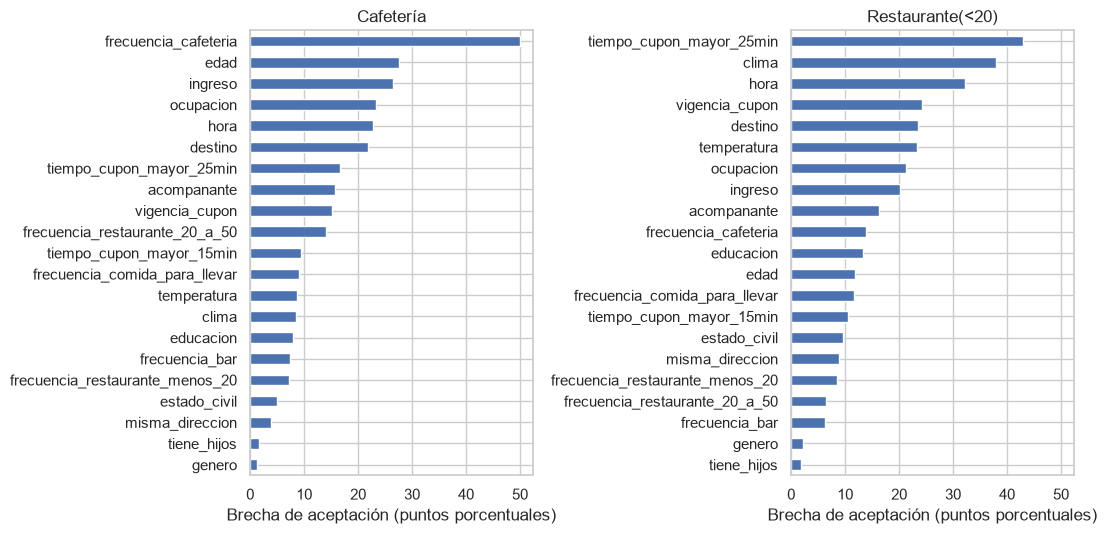

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharex=True)
for ax, nombre in zip(axes, ["Cafetería", "Restaurante(<20)"]):
    tabla_brecha[nombre].sort_values().plot.barh(ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("Brecha de aceptación (puntos porcentuales)")
plt.tight_layout()
plt.show()

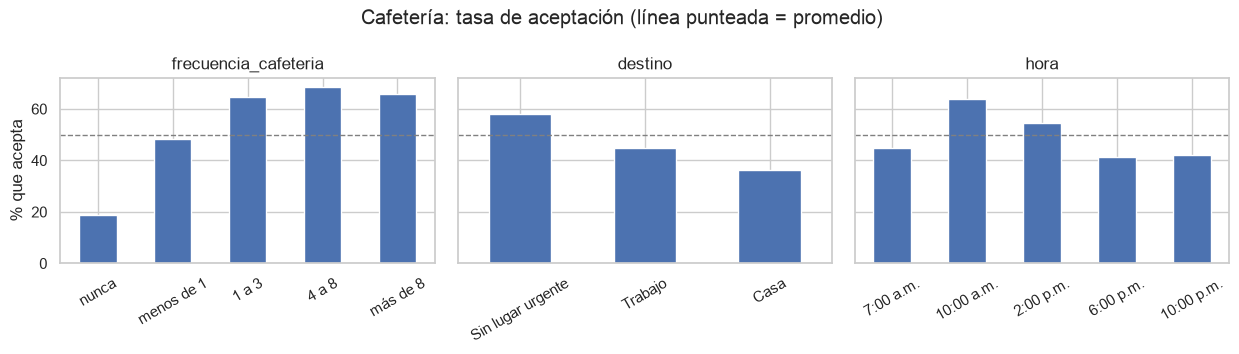

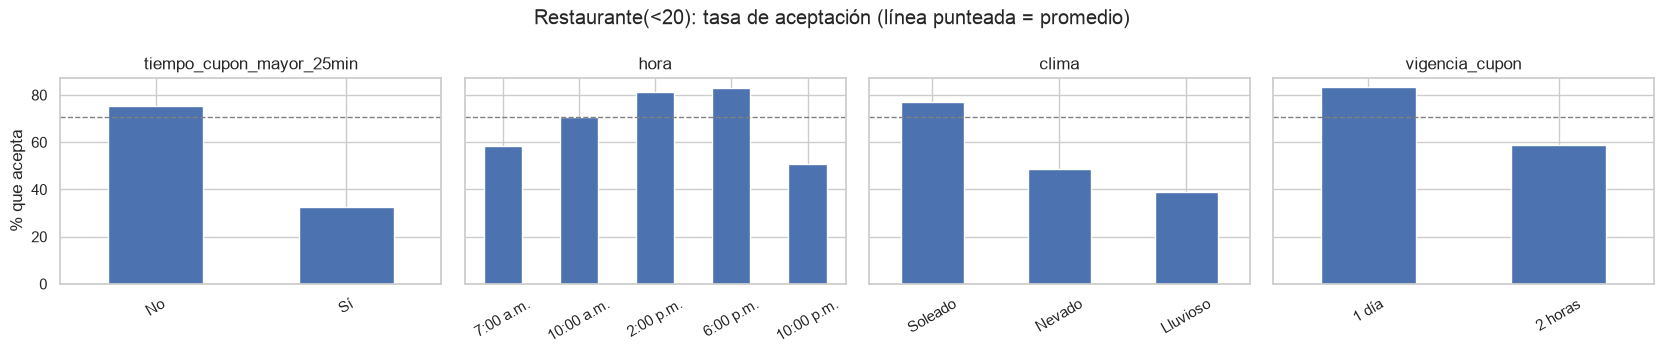

In [19]:
orden_frec = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
orden_hora = ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."]
ordenes = {"frecuencia_cafeteria": orden_frec, "hora": orden_hora}

def graficar_tasas(datos, columnas, titulo):
    fig, axes = plt.subplots(1, len(columnas), figsize=(4.2 * len(columnas), 3.6), sharey=True)
    for ax, col in zip(axes, columnas):
        tasa = (datos["acepta_cupon"] == "Sí").groupby(datos[col]).mean() * 100
        if col in ordenes:
            tasa = tasa.reindex(ordenes[col])
        else:
            tasa = tasa.sort_values(ascending=False)
        tasa.plot.bar(ax=ax)
        ax.axhline((datos["acepta_cupon"] == "Sí").mean() * 100, color="gray", linestyle="--", linewidth=1)
        ax.set_title(col)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=30)
    axes[0].set_ylabel("% que acepta")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

graficar_tasas(cafe, ["frecuencia_cafeteria", "destino", "hora"], "Cafetería: tasa de aceptación (línea punteada = promedio)")
graficar_tasas(rest, ["tiempo_cupon_mayor_25min", "hora", "clima", "vigencia_cupon"], "Restaurante(<20): tasa de aceptación (línea punteada = promedio)")

**Hallazgos.** Cada cupón se explica por cosas distintas. En **Cafetería** pesa el hábito del conductor, pues *frecuencia_cafeteria* tiene la mayor brecha (unos 50 puntos), con 19% de aceptación entre quienes nunca van a cafeterías y entre 65% y 69% entre quienes van varias veces al mes. En **Restaurante(<20)** pesa el contexto del viaje, ya que la distancia, el clima, la hora, la vigencia y el destino tienen brechas de 24 a 43 puntos, mientras que los hábitos del conductor tienen 14 o menos.

*genero*, *tiene_hijos* y *misma_direccion* tienen brechas menores a 10 puntos en ambos cupones. Las variables demográficas (*edad*, *ingreso*, *ocupacion*) muestran diferencias moderadas en Cafetería, aunque algunas categorías son pocas personas (el grupo "menor de 21" tiene 155 filas), y se retoman en el análisis de sesgo.

Algunos efectos no son monótonos, pues en la hora y el ingreso la aceptación sube y baja. Un árbol lo capta, pero una regresión logística con categorías ordenadas solo ve una tendencia lineal, algo a recordar al leer sus coeficientes. Por ahora, ninguna variable se descarta.

### 1.9 Redundancia entre predictoras

Se revisa si algunas predictoras dicen casi lo mismo, porque eso vuelve inestables los coeficientes de la regresión logística. Se miran las parejas más evidentes de 1.6.

In [20]:
ambos = pd.concat([cafe, rest])

for a, b in [("destino", "hora"), ("clima", "temperatura"), ("destino", "misma_direccion")]:
    print(f"{b} según {a} (% por fila):")
    display(pd.crosstab(ambos[a], ambos[b], normalize="index").mul(100).round(0))

hora según destino (% por fila):


hora,10:00 a.m.,10:00 p.m.,2:00 p.m.,6:00 p.m.,7:00 a.m.
destino,,,,,
Casa,0.0,32.0,0.0,68.0,0.0
Sin lugar urgente,31.0,8.0,39.0,22.0,0.0
Trabajo,0.0,0.0,0.0,0.0,100.0


temperatura según clima (% por fila):


temperatura,30,55,80
clima,,,
Lluvioso,0.0,100.0,0.0
Nevado,100.0,0.0,0.0
Soleado,3.0,27.0,70.0


misma_direccion según destino (% por fila):


misma_direccion,No,Sí
destino,,
Casa,51.0,49.0
Sin lugar urgente,100.0,0.0
Trabajo,63.0,37.0


**Hallazgos y decisión.** Las superposiciones vienen del diseño de la encuesta. Ir al trabajo es siempre a las 7:00 a.m., ir a casa solo en la tarde o noche y "sin lugar urgente" a cualquier hora menos las 7:00 a.m., así que *hora* depende mucho de *destino*; además, la nieve es siempre a 30 °F y la lluvia a 55 °F, y sin lugar urgente *misma_direccion* es siempre "No".

Ninguna pareja es un duplicado y cada variable aporta algo propio (en Restaurante, *clima* y *temperatura* tienen brechas grandes), por lo que no se elimina ninguna por redundancia. La colinealidad que queda la controla la regularización, y los árboles no se ven afectados al predecir, aunque pueden repartir la importancia entre variables correlacionadas, algo a tener en cuenta en la Actividad 8.

En resumen, *direccion_opuesta* es redundante (ya eliminada), *destino*/*hora* y *clima*/*temperatura* se solapan en parte, y *genero*, *tiene_hijos*, *misma_direccion* y la constante *tiempo_cupon_mayor_5min* aportan poco.

### 1.10 Contraste con el archivo de prueba

Las predicciones finales se hacen sobre *Lab3_datos_Prueba*, así que se confirma que sea compatible con los datos de entrenamiento.

In [21]:
cols_prueba = [c for c in prueba.columns if c != "conductor"]  # 'conductor' es la clave creada en 1.5
print("Mismas columnas y en el mismo orden (sin la etiqueta):", cols_prueba == [c for c in df.columns if c != "acepta_cupon"])

nuevas = {c: set(prueba[c].dropna()) - set(df[c].dropna()) for c in cols_prueba}
print("Categorías de la prueba que no existen en entrenamiento:", {c: v for c, v in nuevas.items() if v})
print("Nulos en la prueba:", prueba[cols_prueba].isna().sum()[lambda s: s > 0].to_dict())
print("Filas duplicadas en la prueba:", prueba[cols_prueba].duplicated().sum())
print("Cupones en la prueba:", prueba["cupon"].value_counts().to_dict())

Mismas columnas y en el mismo orden (sin la etiqueta): True
Categorías de la prueba que no existen en entrenamiento: {}
Nulos en la prueba: {'vehiculo': 20}
Filas duplicadas en la prueba: 0
Cupones en la prueba: {'Cafetería': 10, 'Restaurante(<20)': 10}


**Hallazgos.** El archivo de prueba tiene las mismas columnas (menos la etiqueta), ninguna categoría nueva y ningún nulo aparte de *vehiculo*, que se elimina. Trae 10 filas de cada cupón y ningún duplicado, de modo que no requiere transformaciones especiales; se aplica el mismo pipeline y cada fila se predice con el modelo de su cupón.

### 1.11 Síntesis de la exploración

La tabla resume lo encontrado por dimensión de calidad y la decisión tomada, que se implementa en la Actividad 2.

| Dimensión | Hallazgo | Decisión |
|:---|:---|:---|
| **Completitud** | *vehiculo* tiene 99.15% de nulos y está vacía en la prueba | Se elimina |
| | *frecuencia_\** tiene entre 0.8% y 1.7% de nulos, por conductor | Imputar con la moda dentro del pipeline |
| **Unicidad** | 7 filas duplicadas exactas por cupón | Se eliminan antes de partir los datos |
| | 4 grupos (Cafetería) y 3 (Restaurante) con las mismas características y etiquetas distintas | Se conservan: es ruido real del problema |
| | Cada conductor aparece en varios escenarios (unos 565) | Riesgo de fuga por grupos: partición estratificada y validación por conductor |
| **Consistencia** (mismo concepto escrito igual) | Sin variantes de escritura ni espacios sobrantes; *ingreso* se escribe distinto en el diccionario y en los datos; *edad* mezcla texto y números | Orden ordinal explícito, con el texto de los datos |
| **Validez** (dentro del dominio y coherente) | Todos los valores están en el dominio del diccionario; *temperatura* solo toma 30, 55 y 80 | Sin acción |
| | Relaciones entre columnas (clima y temperatura, destino y hora, distancias) sin violaciones | Sin acción |
| | *tiempo_cupon_mayor_5min* es constante | Se elimina |
| | 17 casos de "Hijo(s)" sin tener hijos y algunas combinaciones atípicas de edad con ocupación o educación | Se conservan, documentados |
| **Valores atípicos** | No hay variables continuas (solo *temperatura*, con tres valores fijos), así que no aplican los criterios Z ni IQR; hay categorías con menos de 30 filas (4 en Cafetería, 6 en Restaurante) | Se conservan; se controlan con regularización y *min_samples_leaf* |
| **Redundancia** | *direccion_opuesta* es el complemento exacto de *misma_direccion* | Se elimina |
| **Variable objetivo** | Cafetería 50/50; Restaurante 70.7% acepta y 29.3% rechaza | Partición y folds estratificados; F1 macro para elegir hiperparámetros |

De las 26 columnas quedan **21 predictoras** por cupón (se eliminan *vehiculo*, *cupon*, *direccion_opuesta* y *tiempo_cupon_mayor_5min*; *acepta_cupon* es el objetivo).

**Lo que se anticipa.** Cafetería depende sobre todo del hábito del conductor (*frecuencia_cafeteria*) y Restaurante(<20) del contexto del viaje. *genero*, *tiene_hijos* y *frecuencia_bar* casi no se relacionan con la aceptación. Son hipótesis que los modelos deben confirmar.

## <a id="actividad2"></a> Actividad 2 - Limpieza y preparación de los datos

Lo que no depende de los datos de entrenamiento, como quitar columnas inútiles y filas repetidas, se hace directamente antes de partir. Lo que sí aprende de ellos, como la moda para imputar y el escalado, va dentro de un *Pipeline*, para que se calcule solo con el entrenamiento de cada fold y no haya fuga de datos. Se trabaja siempre sobre copias.

### 2.1 Columnas que se eliminan

Se eliminan *vehiculo*, que tiene 99.15% de nulos y está vacía en la prueba, de modo que imputarla sería inventar datos; *cupon*, que es constante dentro de cada subconjunto; *tiempo_cupon_mayor_5min*, que vale "Sí" en el 100% de las filas; y *direccion_opuesta*, que es el complemento exacto de *misma_direccion* y causaría multicolinealidad perfecta.

In [22]:
columnas_eliminar = ["vehiculo", "cupon", "direccion_opuesta", "tiempo_cupon_mayor_5min"]

cafe_limpio = cafe.drop(columns=columnas_eliminar)
rest_limpio = rest.drop(columns=columnas_eliminar)

# Quedan las predictoras, la variable objetivo y la clave 'conductor' (que no se usa como variable)
predictoras_limpio = [c for c in cafe_limpio.columns if c not in ["acepta_cupon", "conductor"]]
print(f"Predictoras por cupón: {len(predictoras_limpio)}")

Predictoras por cupón: 21


### 2.2 Filas duplicadas

Las filas idénticas se eliminan **antes** de partir, para que una fila no quede en el entrenamiento y su copia en la prueba, donde el modelo acertaría solo por haberla visto. Los escenarios iguales con respuestas distintas se conservan, porque no son copias sino ruido real.

In [23]:
n_antes = {"Cafetería": len(cafe_limpio), "Restaurante(<20)": len(rest_limpio)}
cafe_limpio = cafe_limpio.drop_duplicates()
rest_limpio = rest_limpio.drop_duplicates()
n_despues = {"Cafetería": len(cafe_limpio), "Restaurante(<20)": len(rest_limpio)}

print(f"Datos originales sin modificar: {datos_originales.shape}")

resumen_duplicadas = pd.DataFrame({"antes": n_antes, "después": n_despues})
resumen_duplicadas["eliminadas"] = resumen_duplicadas["antes"] - resumen_duplicadas["después"]
resumen_duplicadas

Datos originales sin modificar: (12664, 26)


,antes,después,eliminadas
Cafetería,3986,3979,7
Restaurante(<20),2776,2769,7


Se eliminan 7 filas por subconjunto (menos del 0.3%). Quedan 3979 filas de Cafetería y 2769 de Restaurante(<20).

### 2.3 Partición en entrenamiento y prueba

Cada cupón se parte por separado, 75% para entrenamiento y 25% para prueba, de forma **estratificada** (conserva la proporción de "Sí" y "No") y con semilla fija para que sea reproducible. Se hace antes de ajustar cualquier paso que aprenda de los datos, y el conjunto de prueba no se usa para elegir hiperparámetros ni modelos, solo para evaluarlos al final. La variable objetivo se codifica como Sí = 1 y No = 0, y la clave *conductor* se guarda aparte para la validación por conductor.

In [24]:
def separar(datos):
    X = datos.drop(columns=["acepta_cupon", "conductor"])
    y = (datos["acepta_cupon"] == "Sí").astype(int)
    return train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

X_train_cafe, X_test_cafe, y_train_cafe, y_test_cafe = separar(cafe_limpio)
X_train_rest, X_test_rest, y_train_rest, y_test_rest = separar(rest_limpio)

# Clave de conductor de las filas de entrenamiento (para la validación cruzada por conductor)
grupos_train_cafe = cafe_limpio.loc[X_train_cafe.index, "conductor"]
grupos_train_rest = rest_limpio.loc[X_train_rest.index, "conductor"]

for nombre, datos, Xtr, Xte, ytr, yte, gtr in [
    ("Cafetería", cafe_limpio, X_train_cafe, X_test_cafe, y_train_cafe, y_test_cafe, grupos_train_cafe),
    ("Restaurante(<20)", rest_limpio, X_train_rest, X_test_rest, y_train_rest, y_test_rest, grupos_train_rest),
]:
    visto = datos.loc[Xte.index, "conductor"].isin(gtr).mean()
    print(f"{nombre}: {len(Xtr)} filas de entrenamiento y {len(Xte)} de prueba")
    print(f"   % que acepta: entrenamiento {ytr.mean():.1%}, prueba {yte.mean():.1%} | casos 'No' en prueba: {(yte == 0).sum()}")
    print(f"   filas compartidas entre entrenamiento y prueba: {len(set(Xtr.index) & set(Xte.index))}")
    print(f"   filas de prueba cuyo conductor aparece en entrenamiento: {visto:.1%}")

Cafetería: 2984 filas de entrenamiento y 995 de prueba
   % que acepta: entrenamiento 49.8%, prueba 49.8% | casos 'No' en prueba: 499
   filas compartidas entre entrenamiento y prueba: 0
   filas de prueba cuyo conductor aparece en entrenamiento: 99.4%
Restaurante(<20): 2076 filas de entrenamiento y 693 de prueba
   % que acepta: entrenamiento 70.8%, prueba 70.7% | casos 'No' en prueba: 203
   filas compartidas entre entrenamiento y prueba: 0
   filas de prueba cuyo conductor aparece en entrenamiento: 98.3%


**Hallazgos.** Cafetería queda con 2984 filas de entrenamiento y 995 de prueba, y Restaurante(<20) con 2076 y 693. La proporción de clases se conserva, ninguna fila está en ambos conjuntos y en la prueba de Restaurante quedan 203 casos de "No", suficientes para medir el recall de la clase minoritaria. Se eligió 25% por ese motivo, dentro del rango habitual de 10% a 30%. Los nulos de *frecuencia_\** siguen en ambos conjuntos y se imputan dentro del pipeline.

### 2.4 Preprocesamiento

Se define un *ColumnTransformer* que aplica a cada grupo de columnas su propio tratamiento y que, dentro del *Pipeline* de cada modelo, se reajusta en cada fold solo con sus datos de entrenamiento. Las ordinales (*hora*, *edad*, *educacion*, *ingreso* y las cinco *frecuencia_\**) se imputan con la moda y se codifican como enteros con un orden explícito; las 6 binarias quedan en una columna 0/1 cada una; las nominales (*destino*, *acompanante*, *clima*, *estado_civil*, *ocupacion*) pasan a one-hot, porque no tienen orden; y *temperatura* es la única numérica.

Hay dos variantes. Para la **regresión logística** se estandarizan las ordinales y la temperatura, para que la regularización penalice por igual a las ordinales y a la temperatura, y en los nominales se elimina una categoría de referencia (*drop="first"*) para evitar la multicolinealidad con el intercepto. Para **árboles y Random Forest** no se escala, porque solo usan el orden de los valores.

In [25]:
frecuencias = [c for c in predictoras_limpio if c.startswith("frecuencia_")]

# Orden de las ordinales, escrito con el texto exacto de los datos
orden = {
    "hora": orden_hora,
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo", "Estudios universitarios sin título",
                  "Técnico/Tecnólogo", "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499", "$37.500 - $49.999",
                "$50.000 - $62.499", "$62.500 - $74.999", "$75.000 - $87.499", "$87.500 - $99.999",
                "$100.000 o más"],
}
for col in frecuencias:
    orden[col] = orden_frec

cols_ordinales = list(orden)
cols_binarias = ["genero", "tiene_hijos", "vigencia_cupon", "tiempo_cupon_mayor_15min",
                 "tiempo_cupon_mayor_25min", "misma_direccion"]
cols_nominales = ["destino", "acompanante", "clima", "estado_civil", "ocupacion"]
cols_numericas = ["temperatura"]

El orden de las ordinales se escribe a mano porque, si no, *OrdinalEncoder* las ordena alfabéticamente, y *\$100.000 o más* quedaría como el ingreso más bajo, *10:00 p.m.* antes que *2:00 p.m.* y *menor de 21* como la edad más alta. Además, la lista fija los códigos aunque una categoría rara falte en un fold (*Bachillerato incompleto* tiene 18 filas en Restaurante).

In [26]:
def crear_preprocesador(para_logistica):
    ordinales = [
        ("imp", SimpleImputer(strategy="most_frequent")),
        # Una categoría nueva se codificaría como -1 (en estos datos no ocurre)
        ("cod", OrdinalEncoder(categories=list(orden.values()),
                               handle_unknown="use_encoded_value", unknown_value=-1)),
    ]
    if para_logistica:
        ordinales.append(("esc", StandardScaler()))

    return ColumnTransformer([
        ("ord", Pipeline(ordinales), cols_ordinales),
        ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cols_binarias),
        ("nom", OneHotEncoder(drop="first" if para_logistica else None,
                              handle_unknown="ignore", sparse_output=False), cols_nominales),
        ("num", StandardScaler() if para_logistica else "passthrough", cols_numericas),
    ])

### 2.5 Verificación del preprocesamiento

Se ajusta cada preprocesador solo con entrenamiento y se aplica a entrenamiento y prueba, para comprobar que no quedan nulos y que las columnas coinciden.

In [27]:
assert sorted(cols_ordinales + cols_binarias + cols_nominales + cols_numericas) == sorted(predictoras_limpio)

filas = []
for cupon, Xtr, Xte in [("Cafetería", X_train_cafe, X_test_cafe),
                        ("Restaurante(<20)", X_train_rest, X_test_rest)]:
    for nombre, es_logistica in [("Regresión logística", True), ("Árbol / Random Forest", False)]:
        pre = crear_preprocesador(es_logistica).set_output(transform="pandas")
        Z_train = pre.fit_transform(Xtr)
        Z_test = pre.transform(Xte)
        filas.append({
            "cupón": cupon, "preprocesador": nombre, "columnas": Z_train.shape[1],
            "nulos train": int(Z_train.isna().sum().sum()), "nulos test": int(Z_test.isna().sum().sum()),
            "mismas columnas": list(Z_train.columns) == list(Z_test.columns),
        })
pd.DataFrame(filas)

,cupón,preprocesador,columnas,nulos train,nulos test,mismas columnas
0,Cafetería,Regresión logística,51,0,0,True
1,Cafetería,Árbol / Random Forest,56,0,0,True
2,Restaurante(<20),Regresión logística,51,0,0,True
3,Restaurante(<20),Árbol / Random Forest,56,0,0,True


In [28]:
# Moda con la que se imputan las frecuencias (aprendida solo con el entrenamiento de Cafetería)
imputador = crear_preprocesador(True).fit(X_train_cafe).named_transformers_["ord"].named_steps["imp"]
pd.Series(imputador.statistics_, index=cols_ordinales)[frecuencias].to_frame("moda")

,moda
frecuencia_bar,nunca
frecuencia_cafeteria,menos de 1
frecuencia_comida_para_llevar,1 a 3
frecuencia_restaurante_menos_20,1 a 3
frecuencia_restaurante_20_a_50,menos de 1


**Hallazgos.** Las 21 predictoras quedan cubiertas, sin nulos y con las mismas columnas en entrenamiento y prueba. Quedan 56 columnas para los árboles y 51 para la regresión logística, que elimina una categoría de referencia por variable nominal, y la moda de cada *frecuencia_\** se aprende solo con el entrenamiento. Con esto termina la preparación, y *X_train_\**, *X_test_\**, *y_train_\**, *y_test_\** y *crear_preprocesador* pasan a ser la entrada de las Actividades 3 a 5.

## <a id="actividad3"></a> Actividad 3 - Regresión logística

Se entrena un modelo por cupón, cada uno como un *Pipeline* con el preprocesador de la Actividad 2 y el clasificador, de modo que la imputación y el escalado se reajusten en cada fold. La búsqueda usa *GridSearchCV* con *f1_macro* como métrica y con los mismos folds para todos los modelos, estratificados y separados por conductor (*StratifiedGroupKFold*), porque un mismo conductor aparece en varios escenarios y no debe estar a la vez en entrenamiento y validación. En la Actividad 5 se muestra por qué importa.

Se exploran el tipo de regularización, el solver y *C*. El tipo se elige con *l1_ratio* (0 es L2 y 1 es L1), porque *penalty* quedó obsoleto en scikit-learn 1.8, y no se usa elastic net porque no se vio para clasificación. Con L2 se prueban los solvers *lbfgs*, *liblinear* y *newton-cg*, y con L1 solo *liblinear*, que es el único de los tres que lo admite, por lo que la grilla es una lista de dos diccionarios que evita combinaciones inválidas. *C* es el inverso de la fuerza de regularización y se prueba de 0.001 a 1000 en escala logarítmica. No se usa *class_weight*, porque este es el modelo sin balanceo que la Actividad 6 compara con SMOTE.

In [29]:
pipeline_lr = Pipeline([
    ("pre", crear_preprocesador(para_logistica=True)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

valores_C = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
param_grid_lr = [
    {"clf__l1_ratio": [0], "clf__solver": ["lbfgs", "liblinear", "newton-cg"], "clf__C": valores_C},  # l1_ratio=0 equivale a L2
    {"clf__l1_ratio": [1], "clf__solver": ["liblinear"], "clf__C": valores_C},  # l1_ratio=1 equivale a L1
]

grid_lr_cafe = GridSearchCV(pipeline_lr, param_grid_lr, cv=cv_conductor, scoring="f1_macro", n_jobs=-1)
grid_lr_cafe.fit(X_train_cafe, y_train_cafe, groups=grupos_train_cafe)

grid_lr_rest = GridSearchCV(pipeline_lr, param_grid_lr, cv=cv_conductor, scoring="f1_macro", n_jobs=-1)
grid_lr_rest.fit(X_train_rest, y_train_rest, groups=grupos_train_rest);

In [30]:
def resumir_busqueda(grid, X_train, y_train, nombre):
    mejor = grid.best_index_
    siempre_mayoritaria = np.full(len(y_train), y_train.mode()[0])
    print(nombre)
    print(f"   Mejores hiperparámetros: {grid.best_params_}")
    print(f"   F1 macro en validación cruzada: {grid.best_score_:.3f} ± {grid.cv_results_['std_test_score'][mejor]:.3f}")
    print(f"   F1 macro en entrenamiento:      {f1_score(y_train, grid.predict(X_train), average='macro'):.3f}")
    print(f"   F1 macro prediciendo siempre la clase mayoritaria: {f1_score(y_train, siempre_mayoritaria, average='macro'):.3f}")

def mejores_combinaciones(grid, n=5):
    r = pd.DataFrame(grid.cv_results_)
    columnas = [c for c in r.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score"]
    return r.sort_values("rank_test_score")[columnas].head(n).rename(columns=lambda c: c.replace("param_", "").replace("clf__", "")).round(3)

resumir_busqueda(grid_lr_cafe, X_train_cafe, y_train_cafe, "Cafetería")
resumir_busqueda(grid_lr_rest, X_train_rest, y_train_rest, "Restaurante(<20)")

Cafetería
   Mejores hiperparámetros: {'clf__C': 0.01, 'clf__l1_ratio': 0, 'clf__solver': 'lbfgs'}
   F1 macro en validación cruzada: 0.697 ± 0.020
   F1 macro en entrenamiento:      0.711
   F1 macro prediciendo siempre la clase mayoritaria: 0.334
Restaurante(<20)
   Mejores hiperparámetros: {'clf__C': 1, 'clf__l1_ratio': 0, 'clf__solver': 'lbfgs'}
   F1 macro en validación cruzada: 0.644 ± 0.026
   F1 macro en entrenamiento:      0.665
   F1 macro prediciendo siempre la clase mayoritaria: 0.414


In [31]:
print("Cafetería: mejores combinaciones")
display(mejores_combinaciones(grid_lr_cafe))
print("Restaurante(<20): mejores combinaciones")
display(mejores_combinaciones(grid_lr_rest))

Cafetería: mejores combinaciones


,C,l1_ratio,solver,mean_test_score,std_test_score,rank_test_score
3,0.01,0,lbfgs,0.697,0.020,1
5,0.01,0,newton-cg,0.697,0.020,2
23,0.10,1,liblinear,0.695,0.031,3
4,0.01,0,liblinear,0.693,0.019,4
7,0.10,0,liblinear,0.692,0.028,5


Restaurante(<20): mejores combinaciones


,C,l1_ratio,solver,mean_test_score,std_test_score,rank_test_score
9,1.0,0,lbfgs,0.644,0.026,1
10,1.0,0,liblinear,0.643,0.024,2
11,1.0,0,newton-cg,0.642,0.025,3
24,1.0,1,liblinear,0.641,0.028,4
12,10.0,0,lbfgs,0.640,0.023,5


In [32]:
# Mejor F1 macro en validación cruzada para cada valor de C
def f1_por_C(grid):
    r = pd.DataFrame(grid.cv_results_)
    return r.groupby("param_clf__C")["mean_test_score"].max()

pd.DataFrame({"Cafetería": f1_por_C(grid_lr_cafe), "Restaurante(<20)": f1_por_C(grid_lr_rest)}).rename_axis("C").round(3)

,Cafetería,Restaurante(<20)
C,,
0.001,0.688,0.448
0.010,0.697,0.626
0.100,0.695,0.638
1.000,0.683,0.644
10.000,0.679,0.640
100.000,0.677,0.638
1000.000,0.677,0.637


**Análisis.** En **Cafetería** el mejor modelo usa L2 con *C = 0.01* y llega a un F1 macro de 0.697 en validación cruzada (± 0.020), muy por encima del 0.334 de un modelo que siempre responde lo mismo. Regularizar ayuda un poco, porque el F1 baja a 0.677 con valores grandes de *C* (poca regularización) y también cae a 0.688 con *C = 0.001*, por exceso de penalización. L1 rinde casi igual (0.695) y los solvers coinciden.

En **Restaurante(<20)** el F1 macro es menor, 0.644 (± 0.026) con *C = 1*, frente a 0.414 de la referencia. La curva es plana entre *C = 0.1* y *C = 1000* (0.637 a 0.644), con diferencias mucho menores que la desviación entre folds, y solo cae con una regularización muy fuerte (0.448 con *C = 0.001*).

En ambos cupones el F1 de entrenamiento supera al de validación en apenas 0.014 y 0.021, es decir, no hay sobreajuste notable. Por qué Restaurante es más difícil se retoma en el análisis, y los coeficientes en la Actividad 8.

## <a id="actividad4"></a> Actividad 4 - Árboles de decisión

Se sigue el mismo esquema de la Actividad 3, pero con la variante del preprocesador sin escalado, porque los árboles solo usan el orden de los valores. La grilla cubre lo que pide el enunciado, con *max_depth* de 3, 5, 10 o sin límite, *min_samples_leaf* de 1, 5, 20, 50 o 100, y el criterio *gini* o *entropy*. Un árbol sin restricciones memoriza el entrenamiento, y esos dos hiperparámetros limitan su complejidad. La hoja mínima llega hasta 100 para que el mejor valor quede dentro de la grilla y no en su borde. No se agregan *ccp_alpha*, *max_leaf_nodes* ni *splitter*, porque no se piden y la profundidad junto con la hoja mínima ya controlan el tamaño del árbol.

In [33]:
pipeline_arbol = Pipeline([
    ("pre", crear_preprocesador(para_logistica=False)),
    ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

param_grid_arbol = {
    "clf__max_depth": [3, 5, 10, None],
    "clf__min_samples_leaf": [1, 5, 20, 50, 100],
    "clf__criterion": ["gini", "entropy"],
}

grid_arbol_cafe = GridSearchCV(pipeline_arbol, param_grid_arbol, cv=cv_conductor, scoring="f1_macro", n_jobs=-1)
grid_arbol_cafe.fit(X_train_cafe, y_train_cafe, groups=grupos_train_cafe)

grid_arbol_rest = GridSearchCV(pipeline_arbol, param_grid_arbol, cv=cv_conductor, scoring="f1_macro", n_jobs=-1)
grid_arbol_rest.fit(X_train_rest, y_train_rest, groups=grupos_train_rest);

In [34]:
resumir_busqueda(grid_arbol_cafe, X_train_cafe, y_train_cafe, "Cafetería")
resumir_busqueda(grid_arbol_rest, X_train_rest, y_train_rest, "Restaurante(<20)")

for nombre, grid in [("Cafetería", grid_arbol_cafe), ("Restaurante(<20)", grid_arbol_rest)]:
    arbol = grid.best_estimator_.named_steps["clf"]
    print(f"{nombre}: el árbol elegido tiene profundidad {arbol.get_depth()} y {arbol.get_n_leaves()} hojas")

Cafetería
   Mejores hiperparámetros: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 50}
   F1 macro en validación cruzada: 0.710 ± 0.026
   F1 macro en entrenamiento:      0.723
   F1 macro prediciendo siempre la clase mayoritaria: 0.334
Restaurante(<20)
   Mejores hiperparámetros: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 50}
   F1 macro en validación cruzada: 0.661 ± 0.028
   F1 macro en entrenamiento:      0.659
   F1 macro prediciendo siempre la clase mayoritaria: 0.414
Cafetería: el árbol elegido tiene profundidad 8 y 44 hojas
Restaurante(<20): el árbol elegido tiene profundidad 9 y 32 hojas


In [35]:
print("Cafetería: mejores combinaciones")
display(mejores_combinaciones(grid_arbol_cafe))
print("Restaurante(<20): mejores combinaciones")
display(mejores_combinaciones(grid_arbol_rest))

Cafetería: mejores combinaciones


,criterion,max_depth,min_samples_leaf,mean_test_score,std_test_score,rank_test_score
33,entropy,10,50,0.710,0.026,1
38,entropy,None,50,0.710,0.026,1
8,gini,5,50,0.709,0.029,3
28,entropy,5,50,0.708,0.027,4
18,gini,None,50,0.708,0.026,5


Restaurante(<20): mejores combinaciones


,criterion,max_depth,min_samples_leaf,mean_test_score,std_test_score,rank_test_score
38,entropy,None,50,0.661,0.028,1
33,entropy,10,50,0.661,0.028,1
37,entropy,None,20,0.656,0.029,3
18,gini,None,50,0.656,0.020,4
13,gini,10,50,0.656,0.020,4


In [36]:
# Mejor F1 macro en validación cruzada para cada valor de un hiperparámetro
def mejor_por(grid, parametro):
    r = pd.DataFrame(grid.cv_results_)
    valores = r[f"param_clf__{parametro}"].map(str)  # None = sin límite
    return r.groupby(valores)["mean_test_score"].max()

por_profundidad = pd.DataFrame({
    "Cafetería": mejor_por(grid_arbol_cafe, "max_depth"),
    "Restaurante(<20)": mejor_por(grid_arbol_rest, "max_depth"),
}).reindex(["3", "5", "10", "None"]).rename_axis("max_depth")

por_criterio = pd.DataFrame({
    "Cafetería": mejor_por(grid_arbol_cafe, "criterion"),
    "Restaurante(<20)": mejor_por(grid_arbol_rest, "criterion"),
}).rename_axis("criterion")

por_hoja = pd.DataFrame({
    "Cafetería": mejor_por(grid_arbol_cafe, "min_samples_leaf"),
    "Restaurante(<20)": mejor_por(grid_arbol_rest, "min_samples_leaf"),
}).reindex([str(v) for v in param_grid_arbol["clf__min_samples_leaf"]]).rename_axis("min_samples_leaf")

display(por_profundidad.round(3))
display(por_hoja.round(3))
display(por_criterio.round(3))

,Cafetería,Restaurante(<20)
max_depth,,
3,0.667,0.652
5,0.709,0.655
10,0.710,0.661
None,0.710,0.661


,Cafetería,Restaurante(<20)
min_samples_leaf,,
1,0.685,0.650
5,0.683,0.652
20,0.695,0.656
50,0.710,0.661
100,0.702,0.634


,Cafetería,Restaurante(<20)
criterion,,
entropy,0.710,0.661
gini,0.709,0.656


**Análisis.** En **Cafetería** el mejor árbol usa el criterio *entropy*, profundidad 10 y al menos 50 filas por hoja, con un F1 macro de 0.710 en validación cruzada (± 0.026), cercano al de la regresión logística (0.697). La hoja mínima es lo que más importa, porque con 1 o 5 filas por hoja el árbol rinde 0.683 a 0.685, y mejora con hojas grandes (0.710 con 50 y 0.702 con 100), ya que las hojas pequeñas ajustan casos particulares. Con profundidad 3 el árbol queda corto (0.667), y desde 5 la profundidad casi no importa (0.709 a 0.710), porque la hoja mínima ya limita el tamaño. En **Restaurante(<20)** el patrón es el mismo, con *entropy*, profundidad 10 y hojas de al menos 50 filas, y un F1 macro de 0.661 (± 0.028), por encima de la regresión logística (0.644) aunque dentro de la variación entre folds; con hojas de 100 filas empeora (0.634).

El criterio pesa poco, pues la diferencia entre *entropy* y *gini* es de 0.001 en Cafetería y de 0.005 en Restaurante. El F1 de entrenamiento queda cerca del de validación (0.723 y 0.710 en Cafetería, 0.659 y 0.661 en Restaurante), así que no hay sobreajuste notable. Las reglas del árbol se interpretan en la Actividad 8.

## <a id="actividad5"></a> Actividad 5 - Random Forest

Se sigue el mismo esquema, con el preprocesador sin escalado, porque cada árbol solo usa el orden de los valores. Un Random Forest promedia muchos árboles entrenados sobre muestras distintas y con subconjuntos aleatorios de variables, y por eso tolera árboles profundos; aun así se exploran la profundidad y la hoja mínima por si conviene limitarlos. La grilla cubre lo que pide el enunciado, con el número de árboles (100, 200 y 400), la profundidad máxima (5, 10, 20 o sin límite) y las muestras mínimas por hoja (1, 5, 10 o 20), y suma *max_features* (*sqrt*, 0.3 y 0.6), que S13 destaca como uno de los hiperparámetros más influyentes. No se usa la estimación OOB, porque con conductores repetidos tendría el mismo problema que los folds aleatorios, ni *class_weight*, que se compara en la Actividad 6.

In [37]:
pipeline_rf = Pipeline([
    ("pre", crear_preprocesador(para_logistica=False)),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE)),
])

param_grid_rf = {
    "clf__n_estimators": [100, 200, 400],
    "clf__max_depth": [5, 10, 20, None],
    "clf__min_samples_leaf": [1, 5, 10, 20],
    "clf__max_features": ["sqrt", 0.3, 0.6],
}

grid_rf_cafe = GridSearchCV(pipeline_rf, param_grid_rf, cv=cv_conductor, scoring="f1_macro", n_jobs=-1)
grid_rf_cafe.fit(X_train_cafe, y_train_cafe, groups=grupos_train_cafe)

grid_rf_rest = GridSearchCV(pipeline_rf, param_grid_rf, cv=cv_conductor, scoring="f1_macro", n_jobs=-1)
grid_rf_rest.fit(X_train_rest, y_train_rest, groups=grupos_train_rest);

In [38]:
resumir_busqueda(grid_rf_cafe, X_train_cafe, y_train_cafe, "Cafetería")
resumir_busqueda(grid_rf_rest, X_train_rest, y_train_rest, "Restaurante(<20)")

print("\nCafetería: mejores combinaciones")
display(mejores_combinaciones(grid_rf_cafe))
print("Restaurante(<20): mejores combinaciones")
display(mejores_combinaciones(grid_rf_rest))

Cafetería
   Mejores hiperparámetros: {'clf__max_depth': 5, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 10, 'clf__n_estimators': 200}
   F1 macro en validación cruzada: 0.717 ± 0.023
   F1 macro en entrenamiento:      0.731
   F1 macro prediciendo siempre la clase mayoritaria: 0.334
Restaurante(<20)
   Mejores hiperparámetros: {'clf__max_depth': 10, 'clf__max_features': 0.6, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}
   F1 macro en validación cruzada: 0.665 ± 0.032
   F1 macro en entrenamiento:      0.784
   F1 macro prediciendo siempre la clase mayoritaria: 0.414

Cafetería: mejores combinaciones


,max_depth,max_features,min_samples_leaf,n_estimators,mean_test_score,std_test_score,rank_test_score
19,5,0.3,10,200,0.717,0.023,1
23,5,0.3,20,400,0.717,0.021,2
18,5,0.3,10,100,0.717,0.021,3
20,5,0.3,10,400,0.717,0.022,4
35,5,0.6,20,400,0.716,0.018,5


Restaurante(<20): mejores combinaciones


,max_depth,max_features,min_samples_leaf,n_estimators,mean_test_score,std_test_score,rank_test_score
64,10,0.6,5,200,0.665,0.032,1
65,10,0.6,5,400,0.665,0.034,2
63,10,0.6,5,100,0.664,0.033,3
137,None,0.6,5,400,0.664,0.030,4
101,20,0.6,5,400,0.664,0.030,4


In [39]:
for parametro in ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]:
    valores = [str(v) for v in param_grid_rf[f"clf__{parametro}"]]
    tabla = pd.DataFrame({
        "Cafetería": mejor_por(grid_rf_cafe, parametro),
        "Restaurante(<20)": mejor_por(grid_rf_rest, parametro),
    }).reindex(valores).rename_axis(parametro)
    display(tabla.round(3))

,Cafetería,Restaurante(<20)
n_estimators,,
100,0.717,0.664
200,0.717,0.665
400,0.717,0.665


,Cafetería,Restaurante(<20)
max_depth,,
5,0.717,0.654
10,0.714,0.665
20,0.714,0.664
None,0.714,0.664


,Cafetería,Restaurante(<20)
min_samples_leaf,,
1,0.714,0.661
5,0.716,0.665
10,0.717,0.662
20,0.717,0.657


,Cafetería,Restaurante(<20)
max_features,,
sqrt,0.714,0.656
0.3,0.717,0.662
0.6,0.716,0.665


**Análisis.** El Random Forest queda apenas por encima de los otros modelos, dentro de lo que varía entre folds. En **Cafetería** alcanza un F1 macro de 0.717 (± 0.023), frente a 0.710 del árbol y 0.697 de la regresión logística, y en **Restaurante(<20)** llega a 0.665 (± 0.032), frente a 0.661 y 0.644. En Cafetería los hiperparámetros casi no importan, pues cualquier número de árboles, profundidad u hoja mínima da entre 0.714 y 0.717, y el mejor bosque es poco profundo (profundidad 5), con un F1 de entrenamiento de 0.731, casi igual al de validación. En Restaurante pesa más la profundidad (0.654 con 5 y entre 0.664 y 0.665 desde 10), y el mejor bosque (profundidad 10 y hojas de 5 filas) tiene un entrenamiento de 0.784, 0.12 por encima de la validación; en un bosque el entrenamiento siempre queda inflado, porque cada fila participa en la mayoría de los árboles, así que los algoritmos se comparan con la validación.

### Por qué se valida por conductor

Un Random Forest sin límite de profundidad ni de hoja puede memorizar a los conductores, y con folds aleatorios eso no se castiga, porque el mismo conductor está en entrenamiento y en validación. Para comprobarlo se compara el F1 macro con folds aleatorios y con folds por conductor, para los modelos elegidos y para un bosque sin límite (profundidad libre y hojas de una fila).

In [40]:
def comparar_validaciones(modelos, X_train, y_train, grupos):
    filas = {}
    for nombre, modelo in modelos.items():
        aleatoria = cross_val_score(modelo, X_train, y_train, cv=cv_aleatorio, scoring="f1_macro")
        por_conductor = cross_val_score(modelo, X_train, y_train, cv=cv_conductor, groups=grupos, scoring="f1_macro")
        filas[nombre] = {"folds aleatorios": aleatoria.mean(), "folds por conductor": por_conductor.mean(),
                         "caída": aleatoria.mean() - por_conductor.mean()}
    return pd.DataFrame(filas).T.round(3)

def modelos_a_comparar(grid_lr, grid_arbol, grid_rf):
    rf_sin_limite = clone(grid_rf.best_estimator_).set_params(clf__max_depth=None, clf__min_samples_leaf=1)
    return {"Regresión logística": grid_lr.best_estimator_, "Árbol de decisión": grid_arbol.best_estimator_,
            "Random Forest elegido": grid_rf.best_estimator_, "Random Forest sin límite": rf_sin_limite}

print("Cafetería")
display(comparar_validaciones(modelos_a_comparar(grid_lr_cafe, grid_arbol_cafe, grid_rf_cafe), X_train_cafe, y_train_cafe, grupos_train_cafe))
print("Restaurante(<20)")
display(comparar_validaciones(modelos_a_comparar(grid_lr_rest, grid_arbol_rest, grid_rf_rest), X_train_rest, y_train_rest, grupos_train_rest))

Cafetería


,folds aleatorios,folds por conductor,caída
Regresión logística,0.707,0.697,0.010
Árbol de decisión,0.692,0.710,-0.017
Random Forest elegido,0.719,0.717,0.002
Random Forest sin límite,0.751,0.697,0.054


Restaurante(<20)


,folds aleatorios,folds por conductor,caída
Regresión logística,0.650,0.644,0.006
Árbol de decisión,0.645,0.661,-0.016
Random Forest elegido,0.664,0.665,-0.001
Random Forest sin límite,0.692,0.653,0.039


**Lectura.** El bosque sin límite parece el mejor con folds aleatorios (0.751 en Cafetería y 0.692 en Restaurante), pero con folds por conductor cae a 0.697 y 0.653, por debajo del árbol y del bosque elegidos, es decir, parte de su ventaja era reconocer a conductores ya vistos. Los modelos elegidos casi no cambian entre una validación y otra (la caída es de 0.002 en el bosque de Cafetería y de 0.010 en la regresión logística, y el árbol incluso sube, una diferencia dentro del ruido). Por eso se valida por conductor, que evita elegir un modelo que memoriza y da una estimación más honesta para conductores nuevos.

## <a id="actividad6"></a> Actividad 6 - Balanceo de clases en Restaurante(<20)

En Restaurante solo el 29.3% rechaza el cupón, y los modelos sin balanceo detectan pocos rechazos. Se compara cada algoritmo sin balanceo y con **SMOTE**, que crea observaciones sintéticas de la clase minoritaria. SMOTE va dentro de un *Pipeline* de imblearn, después del preprocesador (ya escalado) y con *k_neighbors=5*, como en P9, para que solo se aplique a los folds de entrenamiento y la validación conserve la proporción real. Con SMOTE se repite la búsqueda con las mismas grillas, porque con datos balanceados el mejor hiperparámetro puede cambiar. Las variantes con balanceo usan el preprocesador escalado de la regresión logística también en árboles y bosques, porque SMOTE mide distancias; en árboles el escalado no cambia las particiones y lo único distinto es que se elimina una categoría de referencia por variable nominal.

Como referencia se agrega *class_weight="balanced"*, que P10 presenta como alternativa a SMOTE, porque penaliza más los errores de la clase minoritaria durante el entrenamiento sin generar datos. Sirve para juzgar si vale la pena crear datos sintéticos. Las métricas salen de la validación por conductor sobre entrenamiento, porque la prueba no se usa para elegir, y además del F1 macro se reporta el recall de "No" (la clase minoritaria) y lo que cuesta, que es la precisión de "No" y el recall de "Sí".

In [41]:
scoring_balanceo = {
    "f1_macro": "f1_macro",
    "recall_No": make_scorer(recall_score, pos_label=0),
    "precision_No": make_scorer(precision_score, pos_label=0, zero_division=0),
    "recall_Si": make_scorer(recall_score, pos_label=1),
}

modelos_balanceo = {
    "Regresión logística": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), param_grid_lr, grid_lr_rest),
    "Árbol de decisión": (DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid_arbol, grid_arbol_rest),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE), param_grid_rf, grid_rf_rest),
}

filas = []
grids_balanceo = {}
for nombre, (clasificador, param_grid, grid_sin_balanceo) in modelos_balanceo.items():
    # Sin balanceo: el mejor modelo de las actividades anteriores
    r = cross_validate(grid_sin_balanceo.best_estimator_, X_train_rest, y_train_rest, cv=cv_conductor, groups=grupos_train_rest,
                       scoring=scoring_balanceo, n_jobs=-1)
    filas.append({"modelo": nombre, "variante": "Sin balanceo", "F1 macro": r["test_f1_macro"].mean(),
                  "desv. F1": r["test_f1_macro"].std(), "recall No": r["test_recall_No"].mean(),
                  "precisión No": r["test_precision_No"].mean(), "recall Sí": r["test_recall_Si"].mean()})

    # Las dos variantes usan el preprocesador escalado, que SMOTE necesita para medir distancias
    pipelines = {
        "SMOTE": ImbPipeline([("pre", crear_preprocesador(para_logistica=True)),
                              ("smote", SMOTE(k_neighbors=5, random_state=RANDOM_STATE)),
                              ("clf", clasificador)]),
        "class_weight": Pipeline([("pre", crear_preprocesador(para_logistica=True)),
                                  ("clf", clone(clasificador).set_params(class_weight="balanced"))]),
    }
    for variante, pipeline in pipelines.items():
        grid = GridSearchCV(pipeline, param_grid, cv=cv_conductor, scoring=scoring_balanceo, refit="f1_macro", n_jobs=-1)
        grid.fit(X_train_rest, y_train_rest, groups=grupos_train_rest)
        grids_balanceo[(nombre, variante)] = grid
        i = grid.best_index_
        filas.append({"modelo": nombre, "variante": variante, "F1 macro": grid.cv_results_["mean_test_f1_macro"][i],
                      "desv. F1": grid.cv_results_["std_test_f1_macro"][i], "recall No": grid.cv_results_["mean_test_recall_No"][i],
                      "precisión No": grid.cv_results_["mean_test_precision_No"][i], "recall Sí": grid.cv_results_["mean_test_recall_Si"][i]})

tabla_balanceo = pd.DataFrame(filas).set_index(["modelo", "variante"]).round(3)
tabla_balanceo

F1 macro  desv. F1  recall No  precisión No  \
modelo              variante                                                    
Regresión logística Sin balanceo     0.644     0.026      0.356         0.621   
                    SMOTE            0.664     0.025      0.620         0.493   
                    class_weight     0.667     0.026      0.608         0.501   
Árbol de decisión   Sin balanceo     0.661     0.028      0.387         0.640   
                    SMOTE            0.662     0.024      0.433         0.583   
                    class_weight     0.652     0.018      0.534         0.503   
Random Forest       Sin balanceo     0.665     0.032      0.386         0.657   
                    SMOTE            0.688     0.026      0.478         0.615   
                    class_weight     0.682     0.034      0.547         0.552   

                                  recall Sí  
modelo              variante                 
Regresión logística Sin balanceo      0.910  
                    SMOTE             0.738  
                    class_weight      0.750  
Árbol de decisión   Sin balanceo      0.909  
                    SMOTE             0.871  
                    class_weight      0.779  
Random Forest       Sin balanceo      0.917  
                    SMOTE             0.877  
                    class_weight      0.816

**Análisis.** En la **regresión logística**, SMOTE sube el F1 macro de 0.644 a 0.664 y, sobre todo, el recall de "No" de 0.36 a 0.62, a costa de una menor precisión de "No" (de 0.62 a 0.49) y de un menor recall de "Sí" (de 0.91 a 0.74), pues al marcar más rechazos también se rechaza a algunos conductores que habrían aceptado. En el **Random Forest** el F1 sube de 0.665 a 0.688 y el recall de "No" de 0.39 a 0.48, y es la mejor combinación de la tabla; en el **árbol** casi no cambia (de 0.661 a 0.662, con un recall de "No" de 0.39 a 0.43). El F1 sube en los tres modelos, pero poco (de 0.001 a 0.023) y dentro de la variación entre folds (± 0.03), de modo que lo que mejora con claridad es el recall de "No". Con *class_weight* el resultado es parecido sin crear datos (F1 de 0.652 a 0.682 y recall de "No" de 0.53 a 0.61), con un recall de "No" mayor que el de SMOTE en el árbol y en el bosque (0.53 y 0.55 frente a 0.43 y 0.48).

**Recomendación.** Sí conviene balancear Restaurante(<20), porque sin balanceo los modelos detectan pocos rechazos (recall de "No" de 0.36 a 0.39 en validación) y el balanceo lo mejora, con un costo en el recall de "Sí". La mejor combinación por F1 es el Random Forest con SMOTE (0.688), que es la que se elige, aunque su ventaja sobre *class_weight* (0.682) no es concluyente; *class_weight* logra un mayor recall de "No" sin inventar datos y es una alternativa igual de válida si se prefiere detectar más rechazos. En prueba se ve lo mismo, pues SMOTE mejora el F1 de los tres modelos (de 0.656 a 0.691, de 0.623 a 0.665 y de 0.679 a 0.687). Un detalle técnico de SMOTE es que, con variables casi todas categóricas, interpola entre filas ya codificadas y genera valores intermedios en columnas 0/1 que no corresponden a una categoría real.

## <a id="actividad7"></a> Actividad 7 - Tabla comparativa de los modelos

Aquí se usa por primera vez el conjunto de prueba, con todos los modelos a la vez. Cada modelo es el mejor de su búsqueda, reentrenado con todo el entrenamiento, y se reportan precisión, recall y F1 con promedio macro, que es coherente con la métrica de selección, más el recall de cada clase para ver qué pasa con los rechazos. Se agregan el F1 de entrenamiento y el de validación por conductor (el que se usó para elegir), para ver si hay sobreajuste, y un bosque sin límite como referencia que no se elige. La regla de selección se fijó antes de mirar la prueba: se elige, para cada cupón, el modelo con mayor F1 macro en validación, y la prueba solo se usa para evaluar.

In [42]:
def metricas_test(modelo, X_test, y_test):
    pred = modelo.predict(X_test)
    return {
        ("Prueba", "Precisión"): precision_score(y_test, pred, average="macro"),
        ("Prueba", "Recall"): recall_score(y_test, pred, average="macro"),
        ("Prueba", "F1"): f1_score(y_test, pred, average="macro"),
        ("Prueba", "Recall No"): recall_score(y_test, pred, pos_label=0),
        ("Prueba", "Recall Sí"): recall_score(y_test, pred, pos_label=1),
    }

def f1_entrenamiento(modelo, X_train, y_train):
    return f1_score(y_train, modelo.predict(X_train), average="macro")

grids_sin_balanceo = {
    "Cafetería": {"Regresión logística": grid_lr_cafe, "Árbol de decisión": grid_arbol_cafe, "Random Forest": grid_rf_cafe},
    "Restaurante(<20)": {"Regresión logística": grid_lr_rest, "Árbol de decisión": grid_arbol_rest, "Random Forest": grid_rf_rest},
}
particiones = {"Cafetería": (X_train_cafe, y_train_cafe, X_test_cafe, y_test_cafe, grupos_train_cafe),
               "Restaurante(<20)": (X_train_rest, y_train_rest, X_test_rest, y_test_rest, grupos_train_rest)}

filas = []
for cupon, modelos in grids_sin_balanceo.items():
    X_tr, y_tr, X_te, y_te, grupos = particiones[cupon]
    for nombre, grid in modelos.items():
        filas.append({("", "Cupón"): cupon, ("", "Modelo"): nombre, **metricas_test(grid.best_estimator_, X_te, y_te),
                      ("F1 macro", "Entrenamiento"): f1_entrenamiento(grid.best_estimator_, X_tr, y_tr),
                      ("F1 macro", "Validación"): grid.best_score_})
    # Referencia que no se elige: un bosque sin límite de profundidad ni de hoja
    bosque = clone(modelos["Random Forest"].best_estimator_).set_params(clf__max_depth=None, clf__min_samples_leaf=1).fit(X_tr, y_tr)
    filas.append({("", "Cupón"): cupon, ("", "Modelo"): "Random Forest sin límite (referencia)", **metricas_test(bosque, X_te, y_te),
                  ("F1 macro", "Entrenamiento"): f1_entrenamiento(bosque, X_tr, y_tr),
                  ("F1 macro", "Validación"): cross_val_score(bosque, X_tr, y_tr, cv=cv_conductor, groups=grupos, scoring="f1_macro").mean()})
tabla_comparativa = pd.DataFrame(filas).set_index([("", "Cupón"), ("", "Modelo")]).rename_axis(["Cupón", "Modelo"]).round(3)
tabla_comparativa

(Prueba, Precisión)  \
Cupón            Modelo                                                       
Cafetería        Regresión logística                                  0.688   
                 Árbol de decisión                                    0.706   
                 Random Forest                                        0.713   
                 Random Forest sin límite (referencia)                0.785   
Restaurante(<20) Regresión logística                                  0.693   
                 Árbol de decisión                                    0.687   
                 Random Forest                                        0.732   
                 Random Forest sin límite (referencia)                0.716   

                                                        (Prueba, Recall)  \
Cupón            Modelo                                                    
Cafetería        Regresión logística                               0.688   
                 Árbol de decisión                                 0.706   
                 Random Forest                                     0.712   
                 Random Forest sin límite (referencia)             0.785   
Restaurante(<20) Regresión logística                               0.644   
                 Árbol de decisión                                 0.614   
                 Random Forest                                     0.664   
                 Random Forest sin límite (referencia)             0.673   

                                                        (Prueba, F1)  \
Cupón            Modelo                                                
Cafetería        Regresión logística                           0.688   
                 Árbol de decisión                             0.706   
                 Random Forest                                 0.711   
                 Random Forest sin límite (referencia)         0.785   
Restaurante(<20) Regresión logística                           0.656   
                 Árbol de decisión                             0.623   
                 Random Forest                                 0.679   
                 Random Forest sin límite (referencia)         0.685   

                                                        (Prueba, Recall No)  \
Cupón            Modelo                                                       
Cafetería        Regresión logística                                  0.697   
                 Árbol de decisión                                    0.705   
                 Random Forest                                        0.673   
                 Random Forest sin límite (referencia)                0.774   
Restaurante(<20) Regresión logística                                  0.394   
                 Árbol de decisión                                    0.310   
                 Random Forest                                        0.409   
                 Random Forest sin límite (referencia)                0.453   

                                                        (Prueba, Recall Sí)  \
Cupón            Modelo                                                       
Cafetería        Regresión logística                                  0.679   
                 Árbol de decisión                                    0.706   
                 Random Forest                                        0.750   
                 Random Forest sin límite (referencia)                0.796   
Restaurante(<20) Regresión logística                                  0.894   
                 Árbol de decisión                                    0.918   
                 Random Forest                                        0.918   
                 Random Forest sin límite (referencia)                0.892   

                                                        (F1 macro, Entrenamiento)  \
Cupón            Modelo                                                             
Cafetería        Regresión logí

In [43]:
# Restaurante(<20) con las variantes de balanceo de la Actividad 6
filas = []
for nombre, grid_sin in grids_sin_balanceo["Restaurante(<20)"].items():
    variantes = [("Sin balanceo", grid_sin)] + [(v, grids_balanceo[(nombre, v)]) for v in ["SMOTE", "class_weight"]]
    for variante, grid in variantes:
        filas.append({("", "Modelo"): nombre, ("", "Variante"): variante,
                      **metricas_test(grid.best_estimator_, X_test_rest, y_test_rest),
                      ("F1 macro", "Entrenamiento"): f1_entrenamiento(grid.best_estimator_, X_train_rest, y_train_rest),
                      ("F1 macro", "Validación"): grid.best_score_})
tabla_restaurante = pd.DataFrame(filas).set_index([("", "Modelo"), ("", "Variante")]).rename_axis(["Modelo", "Variante"]).round(3)
tabla_restaurante

(Prueba, Precisión)  (Prueba, Recall)  \
Modelo              Variante                                              
Regresión logística Sin balanceo                0.693             0.644   
                    SMOTE                       0.685             0.702   
                    class_weight                0.688             0.707   
Árbol de decisión   Sin balanceo                0.687             0.614   
                    SMOTE                       0.690             0.655   
                    class_weight                0.681             0.684   
Random Forest       Sin balanceo                0.732             0.664   
                    SMOTE                       0.696             0.681   
                    class_weight                0.691             0.696   

                                  (Prueba, F1)  (Prueba, Recall No)  \
Modelo              Variante                                          
Regresión logística Sin balanceo         0.656                0.394   
                    SMOTE                0.691                0.631   
                    class_weight         0.695                0.645   
Árbol de decisión   Sin balanceo         0.623                0.310   
                    SMOTE                0.665                0.433   
                    class_weight         0.682                0.562   
Random Forest       Sin balanceo         0.679                0.409   
                    SMOTE                0.687                0.512   
                    class_weight         0.693                0.581   

                                  (Prueba, Recall Sí)  \
Modelo              Variante                            
Regresión logística Sin balanceo                0.894   
                    SMOTE                       0.773   
                    class_weight                0.769   
Árbol de decisión   Sin balanceo                0.918   
                    SMOTE                       0.876   
                    class_weight                0.806   
Random Forest       Sin balanceo                0.918   
                    SMOTE                       0.849   
                    class_weight                0.810   

                                  (F1 macro, Entrenamiento)  \
Modelo              Variante                                  
Regresión logística Sin balanceo                      0.665   
                    SMOTE                             0.678   
                    class_weight                      0.679   
Árbol de decisión   Sin balanceo                      0.659   
                    SMOTE                             0.663   
                    class_weight                      0.676   
Random Forest       Sin balanceo                      0.784   
                    SMOTE                             0.750   
                    class_weight                      0.739   

                                  (F1 macro, Validación)  
Modelo              Variante                              
Regresión logística Sin balanceo                   0.644  
                    SMOTE                          0.664  
                    class_weight                   0.667  
Árbol de decisión   Sin balanceo                   0.661  
                    SMOTE                          0.662  
                    class_weight                   0.652  
Random Forest       Sin balanceo                   0.665  
                    SMOTE                          0.688  
                    class_weight                   0.682

In [44]:
# Selección: el candidato con mayor F1 macro en validación cruzada
candidatos = {
    "Cafetería": {nombre: grid for nombre, grid in grids_sin_balanceo["Cafetería"].items()},
    "Restaurante(<20)": {f"{nombre} ({variante})": grid
                         for nombre, grid_sin in grids_sin_balanceo["Restaurante(<20)"].items()
                         for variante, grid in [("Sin balanceo", grid_sin)] + [(v, grids_balanceo[(nombre, v)]) for v in ["SMOTE", "class_weight"]]},
}

modelo_final = {}
for cupon, grids in candidatos.items():
    mejor = max(grids, key=lambda n: grids[n].best_score_)
    modelo_final[cupon] = grids[mejor].best_estimator_
    print(f"{cupon}: {mejor} (F1 macro en validación cruzada {grids[mejor].best_score_:.3f})")
    print("   hiperparámetros:", {k.replace("clf__", ""): v for k, v in grids[mejor].best_params_.items()})

Cafetería: Random Forest (F1 macro en validación cruzada 0.717)
   hiperparámetros: {'max_depth': 5, 'max_features': 0.3, 'min_samples_leaf': 10, 'n_estimators': 200}
Restaurante(<20): Random Forest (SMOTE) (F1 macro en validación cruzada 0.688)
   hiperparámetros: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 100}


**Análisis.** En **Cafetería** el Random Forest es el mejor también en prueba, con un F1 macro de 0.711 frente a 0.706 del árbol y 0.688 de la regresión logística, diferencias pequeñas que coinciden con la validación (0.717, 0.710 y 0.697). En **Restaurante(<20)** los tres algoritmos sin balanceo quedan entre 0.623 y 0.679 y detectan pocos rechazos (recall de "No" entre 0.31 y 0.41). Con balanceo, el mejor por validación es el Random Forest con SMOTE (0.688), que en prueba obtiene 0.687 y un recall de "No" de 0.51, y con *class_weight* el bosque obtiene 0.693 y 0.58.

El bosque sin límite, que se incluye solo como referencia, obtiene 0.785 en la prueba de Cafetería, mucho más que el elegido, pero con un F1 de entrenamiento de 0.999 y una validación por conductor de 0.697. Esa ventaja viene de reconocer a conductores que también están en el entrenamiento, y por eso no se elige: se prefiere un modelo que no dependa de memorizar, aunque en esta prueba, de conductores conocidos, obtenga menos.

**Selección.** Siguiendo la regla, el modelo elegido es el Random Forest para Cafetería (F1 macro de 0.717 en validación por conductor) y el Random Forest con SMOTE para Restaurante(<20) (0.688). La prueba coincide con la validación en ambos casos (0.711 frente a 0.717 y 0.687 frente a 0.688), aunque en Restaurante otras variantes obtienen algo más en prueba (por ejemplo *class_weight*, con 0.693), diferencias que están dentro del ruido y no cambian la elección, porque la regla se fijó antes. Las diferencias entre algoritmos son pequeñas y caen dentro de la desviación entre folds (de 0.02 a 0.03), así que la elección no es concluyente. Los modelos elegidos tienen una diferencia moderada entre entrenamiento y validación (0.73 y 0.72 en Cafetería, 0.75 y 0.69 en Restaurante), sin memorizar, y como la prueba contiene conductores ya vistos, sus F1 son algo optimistas para conductores nuevos.

## <a id="actividad8"></a> Actividad 8 - Variables más relevantes

La relevancia se mide en el modelo elegido de cada cupón con dos medidas. La **importancia por impureza**, que muestra P10, suma cuánto reduce cada variable la impureza de los nodos en todos los árboles; se calcula sobre las columnas ya codificadas, así que aquí se suma por variable original. La **importancia por permutación** mezcla al azar los valores de una variable en el conjunto de prueba y mide cuánto baja el F1 macro (30 repeticiones); no depende de cómo se construyó el árbol ni favorece a las variables con muchas categorías. Ninguna de las dos demuestra causalidad.

In [45]:
todas_las_variables = cols_ordinales + cols_binarias + cols_nominales + cols_numericas

def variable_original(columna):
    # Variable de origen de una columna del preprocesador (por ejemplo nom__destino_Casa -> destino)
    nombre = columna.split("__", 1)[1]
    candidatas = [v for v in todas_las_variables if nombre == v or nombre.startswith(v + "_")]
    return max(candidatas, key=len)

importancias = {}
for cupon, X_te, y_te in [("Cafetería", X_test_cafe, y_test_cafe), ("Restaurante(<20)", X_test_rest, y_test_rest)]:
    modelo = modelo_final[cupon]
    columnas = modelo.named_steps["pre"].get_feature_names_out()
    # Los dos modelos finales son bosques, que traen feature_importances_
    por_impureza = pd.Series(modelo.named_steps["clf"].feature_importances_, index=columnas).groupby(variable_original).sum()
    permutacion = permutation_importance(modelo, X_te, y_te, scoring="f1_macro", n_repeats=30,
                                         random_state=RANDOM_STATE, n_jobs=-1)
    importancias[cupon] = pd.DataFrame({
        "Permutación": permutacion.importances_mean,
        "Desv. permutación": permutacion.importances_std,
        "Impureza": por_impureza,
    }, index=X_te.columns).sort_values("Permutación", ascending=False)

for cupon, tabla in importancias.items():
    print(f"{cupon}: 10 variables más relevantes")
    display(tabla.head(10).round(3))

Cafetería: 10 variables más relevantes


,Permutación,Desv. permutación,Impureza
frecuencia_cafeteria,0.143,0.013,0.469
destino,0.036,0.011,0.105
vigencia_cupon,0.030,0.007,0.094
misma_direccion,0.012,0.003,0.027
hora,0.009,0.005,0.051
acompanante,0.008,0.004,0.052
tiempo_cupon_mayor_15min,0.006,0.002,0.019
edad,0.003,0.001,0.018
temperatura,0.003,0.002,0.015
frecuencia_restaurante_menos_20,0.002,0.001,0.011


Restaurante(<20): 10 variables más relevantes


,Permutación,Desv. permutación,Impureza
vigencia_cupon,0.027,0.008,0.174
destino,0.008,0.009,0.088
clima,0.004,0.007,0.077
tiempo_cupon_mayor_15min,0.002,0.005,0.032
genero,0.001,0.004,0.018
temperatura,-0.000,0.006,0.044
tiempo_cupon_mayor_25min,-0.000,0.004,0.053
frecuencia_restaurante_menos_20,-0.001,0.004,0.027
frecuencia_cafeteria,-0.001,0.003,0.031
educacion,-0.002,0.005,0.040


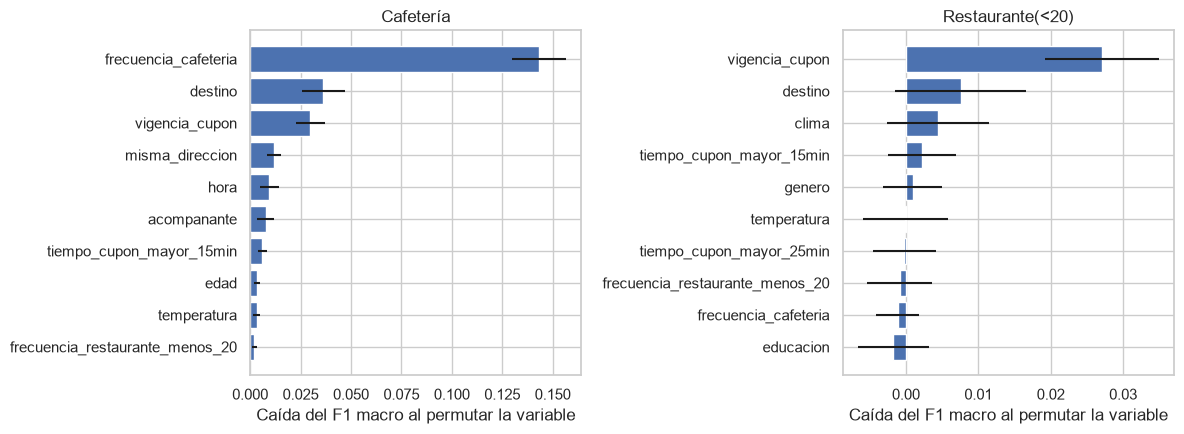

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (cupon, tabla) in zip(axes, importancias.items()):
    top = tabla.head(10).iloc[::-1]
    ax.barh(top.index, top["Permutación"], xerr=top["Desv. permutación"])
    ax.set_title(cupon)
    ax.set_xlabel("Caída del F1 macro al permutar la variable")
plt.tight_layout()
plt.show()

En las reglas del árbol las variables ordinales aparecen ya codificadas como números, de modo que *frecuencia_cafeteria <= 0.50* significa *nunca*, y *tiempo_cupon_mayor_25min_Sí* es la distancia mayor a 25 minutos.

In [47]:
for cupon, grid in [("Cafetería", grid_arbol_cafe), ("Restaurante(<20)", grid_arbol_rest)]:
    arbol = grid.best_estimator_
    print(cupon)
    print(export_text(arbol.named_steps["clf"], feature_names=list(arbol.named_steps["pre"].get_feature_names_out()), max_depth=2))

Cafetería
|--- ord__frecuencia_cafeteria <= 0.50
|   |--- ord__ingreso <= 5.50
|   |   |--- ord__frecuencia_restaurante_20_a_50 <= 1.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- ord__frecuencia_restaurante_20_a_50 >  1.50
|   |   |   |--- class: 0
|   |--- ord__ingreso >  5.50
|   |   |--- ord__frecuencia_bar <= 1.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- ord__frecuencia_bar >  1.50
|   |   |   |--- class: 0
|--- ord__frecuencia_cafeteria >  0.50
|   |--- ord__frecuencia_cafeteria <= 1.50
|   |   |--- nom__destino_Sin lugar urgente <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- nom__destino_Sin lugar urgente >  0.50
|   |   |   |--- truncated branch of depth 4
|   |--- ord__frecuencia_cafeteria >  1.50
|   |   |--- bin__vigencia_cupon_2 horas <= 0.50
|   |   |   |--- truncated branch of depth 6
|   |   |--- bin__vigencia_cupon_2 horas >  0.50
|   |   |   |--- truncated branch of depth 5

Restaurante(<20)
|--- bin__tiempo_cupon_mayor

**Análisis.** En **Cafetería** la variable más relevante es, con mucha diferencia, *frecuencia_cafeteria*: al mezclar sus valores el F1 macro baja 0.143, cuatro veces más que con la siguiente (*destino*, 0.036), y también es la primera por impureza y la primera pregunta del árbol, que separa a quienes nunca van a cafeterías. Le siguen *destino* y *vigencia_cupon* (0.030), de modo que el hábito del conductor pesa más que el contexto del viaje, y el resto aporta poco (0.012 o menos cada una). En **Restaurante(<20)** la señal es débil, porque solo *vigencia_cupon* destaca (0.027), seguida de *destino* (0.008) y *clima* (0.004). El árbol de Restaurante abre con la distancia (más de 25 minutos), que en el bosque no aporta (0.000), posiblemente porque afecta a una parte pequeña de los escenarios y otras variables la reemplazan; las reglas vienen del mejor árbol y las importancias del bosque final, que son modelos distintos.

Hay que leer estos resultados con cuidado. En Restaurante casi todas las importancias son del tamaño de su desviación o negativas, lo que sugiere que esas variables no aportan o incluso perjudican, y que la señal se concentra en muy pocas. Las dos medidas coinciden en la primera variable de cada cupón, pero después los órdenes cambian, y la importancia por impureza tiende a favorecer a las variables con muchas categorías, por lo que se da más peso a la de permutación. Además, la prueba contiene conductores ya vistos, así que parte de la importancia puede venir de reconocer a la persona. Se trata de asociaciones, no de causas.

## <a id="actividad10"></a> Actividad 10 - Predicciones sobre los datos de prueba

Se predice el archivo sin etiquetas con el modelo elegido para cada cupón, entrenado solo con el conjunto de entrenamiento, como en las prácticas. A cada fila se le aplica el modelo de su cupón y el resultado se guarda en el archivo *Lab3_datos_Prueba.csv*, con las mismas columnas y el mismo orden del archivo original, más la columna *acepta_cupon*.

In [48]:
X_prueba = prueba[predictoras_limpio]
predicciones = pd.Series(index=prueba.index, dtype=object)
for cupon, modelo in modelo_final.items():
    # Cada fila se predice con el modelo de su cupón
    mascara = prueba["cupon"] == cupon
    predicciones[mascara] = np.where(modelo.predict(X_prueba[mascara]) == 1, "Sí", "No")

resultado = prueba_original.copy()
resultado["acepta_cupon"] = predicciones
resultado.to_csv("Lab3_datos_Prueba.csv", index=False)

print(f"Filas: {len(resultado)} | columnas: {resultado.shape[1]} | predicciones sin asignar: {resultado['acepta_cupon'].isna().sum()}")
pd.crosstab(resultado["cupon"], resultado["acepta_cupon"])

Filas: 20 | columnas: 26 | predicciones sin asignar: 0


acepta_cupon,No,Sí
cupon,,
Cafetería,5,5
Restaurante(<20),2,8


Se predijeron las 20 filas, 10 por cupón. En Cafetería el modelo predice 5 aceptaciones y 5 rechazos, y en Restaurante(<20) 8 aceptaciones y 2 rechazos, una proporción parecida a la del entrenamiento. El archivo conserva las 25 columnas originales y el orden de las filas, con *acepta_cupon* como columna final. Como solo son 20 filas, el F1 sobre este archivo es muy sensible a un solo error y no sirve para comparar modelos.

## <a id="analisis"></a> Análisis de resultados

Las respuestas se apoyan en las tablas y gráficos de las actividades anteriores y en dos tablas más, las variables menos relevantes y el desempeño por grupo de los modelos elegidos sobre la prueba. Para esa tabla, la edad se agrupa en menos de 26, 26 a 35 y 36 o más, el ingreso en tres niveles de tres categorías del diccionario cada uno, y el estado civil en con o sin pareja.

In [49]:
for cupon, tabla in importancias.items():
    print(f"{cupon}: 6 variables menos relevantes por permutación")
    display(tabla.tail(6).round(3))

Cafetería: 6 variables menos relevantes por permutación


,Permutación,Desv. permutación,Impureza
genero,0.001,0.001,0.006
frecuencia_bar,0.001,0.001,0.013
estado_civil,0.001,0.001,0.012
frecuencia_restaurante_20_a_50,0.000,0.000,0.011
tiempo_cupon_mayor_25min,0.000,0.000,0.004
educacion,-0.000,0.001,0.013


Restaurante(<20): 6 variables menos relevantes por permutación


,Permutación,Desv. permutación,Impureza
edad,-0.005,0.005,0.033
hora,-0.005,0.008,0.082
frecuencia_bar,-0.005,0.003,0.025
ingreso,-0.009,0.005,0.037
estado_civil,-0.010,0.005,0.039
tiene_hijos,-0.010,0.005,0.021


In [50]:
# Edad e ingreso se agrupan en tres niveles, y el estado civil en con o sin pareja
grupo_edad = {"menor de 21": "Menos de 26", "21": "Menos de 26", "26": "26 a 35", "31": "26 a 35",
              "36": "36 o más", "41": "36 o más", "46": "36 o más", "50 o más": "36 o más"}
nivel_ingreso = {valor: ("Bajo" if i < 3 else "Medio" if i < 6 else "Alto") for i, valor in enumerate(orden["ingreso"])}
grupo_pareja = {"Casado(a)": "Con pareja", "Unión libre": "Con pareja", "Soltero(a)": "Sin pareja",
                "Divorciado(a)": "Sin pareja", "Viudo(a)": "Sin pareja"}

def desempeno_por_grupo(cupon, X_te, y_te, grupos, orden_grupos):
    pred = pd.Series(modelo_final[cupon].predict(X_te), index=X_te.index)
    resultados = {}
    for grupo in orden_grupos:
        idx = grupos.index[grupos == grupo]
        real, predicho = y_te.loc[idx], pred.loc[idx]
        resultados[grupo] = {"n": len(idx), "% acepta (real)": real.mean() * 100, "% con oferta (predicho)": predicho.mean() * 100,
                             "Recall Sí": recall_score(real, predicho, pos_label=1), "Recall No": recall_score(real, predicho, pos_label=0)}
    return pd.DataFrame(resultados).T.astype({"n": int}).round(2)

for cupon, X_te, y_te in [("Cafetería", X_test_cafe, y_test_cafe), ("Restaurante(<20)", X_test_rest, y_test_rest)]:
    print(cupon)
    for nombre, grupos, niveles in [("Género", X_te["genero"], ["Femenino", "Masculino"]),
                                    ("Edad", X_te["edad"].map(grupo_edad), ["Menos de 26", "26 a 35", "36 o más"]),
                                    ("Estado civil", X_te["estado_civil"].map(grupo_pareja), ["Con pareja", "Sin pareja"]),
                                    ("Ingreso del hogar", X_te["ingreso"].map(nivel_ingreso), ["Bajo", "Medio", "Alto"])]:
        display(desempeno_por_grupo(cupon, X_te, y_te, grupos, niveles).rename_axis(nombre))

Cafetería


,n,% acepta (real),% con oferta (predicho),Recall Sí,Recall No
Género,,,,,
Femenino,503,49.11,56.26,0.79,0.65
Masculino,492,50.61,51.22,0.71,0.70


,n,% acepta (real),% con oferta (predicho),Recall Sí,Recall No
Edad,,,,,
Menos de 26,257,54.86,61.09,0.81,0.63
26 a 35,382,52.09,57.33,0.76,0.63
36 o más,356,43.82,44.66,0.69,0.74


,n,% acepta (real),% con oferta (predicho),Recall Sí,Recall No
Estado civil,,,,,
Con pareja,560,49.11,53.57,0.76,0.68
Sin pareja,435,50.80,54.02,0.74,0.66


,n,% acepta (real),% con oferta (predicho),Recall Sí,Recall No
Ingreso del hogar,,,,,
Bajo,386,49.22,53.11,0.75,0.68
Medio,353,51.84,53.82,0.73,0.66
Alto,256,48.05,54.69,0.78,0.67


Restaurante(<20)


,n,% acepta (real),% con oferta (predicho),Recall Sí,Recall No
Género,,,,,
Femenino,365,70.68,74.25,0.85,0.52
Masculino,328,70.73,74.39,0.84,0.50


,n,% acepta (real),% con oferta (predicho),Recall Sí,Recall No
Edad,,,,,
Menos de 26,160,76.25,78.75,0.87,0.47
26 a 35,252,74.60,74.21,0.81,0.47
36 o más,281,64.06,71.89,0.87,0.55


,n,% acepta (real),% con oferta (predicho),Recall Sí,Recall No
Estado civil,,,,,
Con pareja,403,73.70,72.70,0.82,0.55
Sin pareja,290,66.55,76.55,0.89,0.47


,n,% acepta (real),% con oferta (predicho),Recall Sí,Recall No
Ingreso del hogar,,,,,
Bajo,272,73.16,82.72,0.93,0.47
Medio,231,71.43,70.56,0.81,0.55
Alto,190,66.32,66.84,0.77,0.53


**1. ¿Qué características del contexto o del perfil parecen más relacionadas con la aceptación de cada cupón?** En Cafetería pesa sobre todo el perfil del conductor. *frecuencia_cafeteria* es la variable más relevante por mucha diferencia (al permutarla el F1 macro baja 0.143, frente a 0.036 de la siguiente) y, según la exploración, la aceptación pasa de 19% entre quienes nunca van a cafeterías a entre 65% y 69% entre quienes van varias veces al mes; le siguen el destino y la vigencia del cupón. En Restaurante(<20) pesa más el contexto del viaje, con la vigencia del cupón como variable más relevante (0.027), seguida del destino y el clima, y en la exploración la distancia, el clima y la vigencia tienen brechas de aceptación de 24 a 43 puntos.

**2. ¿Existen variables redundantes o poco informativas?** Sí. Es redundante *direccion_opuesta*, el complemento exacto de *misma_direccion* (ya eliminada), y se solapan en parte *destino* con *hora* y *clima* con *temperatura* por el diseño de la encuesta. Poco informativas son *tiempo_cupon_mayor_5min*, que es constante y se eliminó, y, según las tablas anteriores, en Cafetería *genero*, *frecuencia_bar*, *estado_civil*, *educacion*, *frecuencia_restaurante_20_a_50* y la distancia de 25 minutos, con importancias de 0.001 o menos, y en Restaurante *edad*, *hora*, *frecuencia_bar*, *ingreso*, *estado_civil* y *tiene_hijos*, con importancias negativas, lo que sugiere que el modelo no depende de ellas o incluso se confunde con ellas. En Restaurante, *hora* o *ingreso* mostraban diferencias de aceptación en la exploración, pero el modelo no las usa de forma estable, posiblemente porque están ligadas a otras como *destino*. Se conservaron porque quitarlas no se justificaba antes de modelar, y habría que reajustar sin ellas para confirmar que no hacen falta.

**3. ¿El desempeño y el comportamiento difieren entre Cafetería y Restaurante(<20)? ¿A qué se atribuye?** Sí, sobre todo en cómo falla cada modelo. El F1 macro de validación es algo mayor en Cafetería (0.717 frente a 0.688), una diferencia del orden de la desviación entre folds, pero en Restaurante, sin balanceo, los modelos detectan pocos rechazos (recall de "No" entre 0.31 y 0.41 en prueba), mientras que en Cafetería, que está balanceada, ese recall es de 0.67 a 0.71. Probablemente se debe a dos cosas. La primera es el desbalance, porque en Restaurante solo el 29.3% rechaza y hay menos ejemplos de la clase difícil. La segunda es el tipo de señal, ya que en Cafetería una variable del conductor (*frecuencia_cafeteria*) concentra mucha información (0.143), mientras que en Restaurante solo destaca la vigencia del cupón, con poco peso (0.027), lo que da una señal más difusa. No se aisló el efecto de cada causa.

**4. ¿Aplicar balanceo en Restaurante(<20) mejoró el modelo?** Sí, con matices. Con SMOTE el F1 macro sube de 0.644 a 0.664 en la regresión logística, de 0.665 a 0.688 en el Random Forest y casi nada en el árbol (de 0.661 a 0.662), mejoras pequeñas y dentro de la variación entre folds. El recall de la clase minoritaria sube más, de 0.36 a 0.62 en la regresión logística y de 0.39 a 0.48 en el Random Forest, a costa de una menor precisión de "No" y de un menor recall de "Sí". Por eso se recomienda balancear, con SMOTE o con *class_weight*, que logra un recall de "No" parecido o mayor (0.53 a 0.61) sin crear datos sintéticos, según se quiera priorizar el F1 o la detección de rechazos.

**5. ¿Qué reglas o importancias explican aceptar o rechazar, y qué utilidad y limitación tiene esa interpretación?** En Cafetería el árbol (profundidad 8 y 44 hojas) pregunta primero si el conductor nunca va a cafeterías; si va menos de una vez al mes se mira el destino, si va más seguido la vigencia del cupón, y si nunca va, el ingreso y luego los hábitos de consumo. En Restaurante(<20) el árbol (32 hojas) pregunta primero si el establecimiento queda a más de 25 minutos; si no, mira la vigencia del cupón y luego el acompañante o la hora, y si es lejos, predice rechazo a las 10 p.m. y, antes, mira con qué frecuencia va a bares. En Cafetería la importancia por permutación del bosque señala las mismas variables principales; en Restaurante coincide solo en la vigencia, y la distancia, que abre el árbol, no aporta en el bosque. La utilidad es que se puede explicar una decisión en términos de negocio y comprobar si tiene sentido. Las limitaciones son que un árbol es inestable (cambia con pocos datos) y de fronteras escalonadas, que en un bosque de cientos de árboles se pierde la lectura del camino, y que la importancia no indica la dirección del efecto, no prueba causalidad y puede incluir el reconocimiento de conductores.

**6. ¿Cómo podría integrarse este modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?** Cada modelo es un pipeline completo, con el preprocesamiento incluido, así que puede guardarse y cargarse en el servicio de la aplicación (por ejemplo con joblib, como en las prácticas). Cuando el conductor entra a un escenario se arma un registro con el contexto (destino, hora, clima, acompañante, vigencia) y con su perfil y hábitos guardados, se calcula con *predict_proba* la probabilidad de aceptación de cada cupón candidato y se muestra el de mayor probabilidad si supera un umbral. El umbral debe fijarse según el costo de los errores y no en 0.5, porque mostrar un cupón que se rechaza molesta, algo que la empresa ya mencionó, y no mostrar uno que se habría aceptado pierde una oportunidad. Hay que tener cuidado al comparar probabilidades de dos modelos entrenados por separado, que no están calibradas, y más aún con SMOTE, que desplaza las probabilidades del modelo de Restaurante. También conviene medir la latencia y monitorear en producción la tasa de aceptación real y la deriva de los datos, para reentrenar cuando se degrade.

**7. ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar según el perfil demográfico?** Una limitación importante es el riesgo de sobrestimar el desempeño por reconocer a los conductores. Con los modelos elegidos el efecto es pequeño (en Cafetería 0.719 con folds aleatorios frente a 0.717 por conductor), pero un bosque sin límite pasa de 0.751 a 0.697, y en una prueba de conductores conocidos daría un F1 mayor (0.785 en Cafetería), ventaja que desaparece con un conductor nuevo y sin historial, el llamado problema del arranque en frío. Además, el modelo aprende de lo que los encuestados dijeron que harían y no de lo que hicieron, representa a un grupo concreto de personas, y puede reforzarse a sí mismo, porque si solo se muestran cupones a quienes el modelo cree que aceptarán, los datos futuros tendrán solo a esos conductores. Por último, el desempeño no es parejo entre grupos, como se ve en la tabla anterior, de modo que un error afecta más a unos que a otros.

**8. ¿Qué fuentes de sesgo hay al usar variables como edad, género, estado civil o ingreso, y qué implicaría usar esta personalización en otros fines, como precios dinámicos?** En la tabla por grupo, el modelo reproduce las diferencias de aceptación y en algunos casos ofrece de más. En Cafetería, los mayores de 35 aceptan menos (43.8% frente a 52% y 55%), el modelo les ofrece menos cupones (44.7% frente a 57.3% y 61.1%) y detecta peor a quienes sí habrían aceptado (recall de "Sí" de 0.69 frente a 0.81 en los menores de 26). En Restaurante hay sobreoferta en algunos grupos, pues a los hogares de ingreso bajo se les ofrece el cupón en el 82.7% de los casos aunque lo aceptan el 73.2%, y a quienes no tienen pareja en el 76.6% frente a 66.6%, mientras que en los hogares de ingreso alto la oferta (66.8%) coincide con la aceptación (66.3%) pero se detecta peor a quienes sí aceptarían (recall de "Sí" de 0.77 frente a 0.93 en ingreso bajo). Esto se relaciona con dos criterios de equidad, la paridad demográfica (misma tasa de oferta entre grupos) y la igualdad de oportunidad (mismo recall de "Sí"), que aquí no se cumplen. Por género, y en Cafetería también por ingreso y estado civil, las diferencias son pequeñas, y con grupos de 160 a 560 filas las diferencias pequeñas pueden ser ruido.

Las fuentes de sesgo son la muestra (la fuente original es una encuesta en línea, cuyos participantes no representan a todos los conductores), las etiquetas (intención declarada y no comportamiento), las variables proxy (ocupación, ingreso y edad se relacionan con el género y otras características, y quitar la variable sensible podría no bastar), la agregación (un solo modelo rinde distinto según el grupo) y la retroalimentación (lo que se muestra condiciona lo que se observa). Con cupones el daño es limitado, pero con precios dinámicos sería mucho mayor, porque dos personas en la misma situación pagarían precios distintos según su perfil, y diferencias que hoy parecen inocuas, como ofrecer más a los hogares de ingreso bajo, se convertirían en discriminación de precios, con riesgos legales y de confianza. Para mitigarlo conviene medir siempre el desempeño por grupo, delimitar el uso del modelo, revisar las variables sensibles y sus proxies, y mantener supervisión humana.